# 03a — NPV winner check and mixed-build optimizer

This notebook asks two questions about the choice between the two pure nuclear programs. A
**pure program** builds a whole deployment target with one technology: either 100 % large
light-water reactors (1 GW units) or 100 % small modular reactors (SMRs, 0.3 GW units).
Section A asks whether the cheaper program changes when the ranking counts operating costs
(fixed O&M, variable O&M and fuel) as well as financed capital cost. Section B asks whether any
split of the program between the two technologies beats the better pure program. Section C
composes Supplementary Figure 5 from the Section B panels and one panel of notebook 01.

**Inputs**
- `results/exports/01/mc_perdraw.npz` — the per-draw Monte Carlo record (notebook 01). Section A only.
- `results/exports/01/fragmentation_hist.png` — the fragmentation-penalty panel (notebook 01). Section C only.
- ReEDS fork inputs under `inputs/`: `nuclear_learning/US_SCHEDULES.csv`, `nuclear_learning/rds2_2025_units.csv`,
  `financials/*`, `plant_characteristics/*` (ATB 2024 nuclear rows, outage curves), `fuelprices/uranium_AEO_2026_baseline.csv`,
  `tech-subset-table.csv`.
- `data/reeds_inputs/` — frozen slices of one local ReEDS run and of the ReEDS temperature table (see that folder's README).

**Outputs** (`results/exports/03a/`)
- `npv_winner_summary.csv`, `npv_flips.csv` (Section A; notebook 03b reads both).
- `mixed_build/verdict_by_schedule.csv`, `mixed_build/winning_draws.csv`, `mixed_build/xzero_verdict.csv`,
  `mixed_build/mixed_build_metadata.json` (Section B).
- Panel sources `mixed_build_advantage.png`, `mixed_build_margin_map.png`, `mixed_build_parameter_space.png`,
  and the diagnostic `np_npv_margin_scatter.png`.
- `results/figures/si/SF05_mixed_build.png` (Section C).

**Paper items:** Supplementary Figure 5 (panels a–e from Section B, panel f from notebook 01). Section A
supplies the NPV win probabilities that notebook 03b uses for Supplementary Figures 4, 6 and 7.

**Runtime:** about 17 minutes on the reference machine (4 threads). Section A takes about 1 minute;
the mixed-build optimizer takes the rest. Run it detached if your shell kills long jobs.

In [1]:
import sys
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "nlpaper").is_dir():           # find z-ethan/ from wherever the kernel starts
    _p = _p.parent
sys.path.insert(0, str(_p))
import nlpaper
from nlpaper import paths, plotstyle as ps, h5io
nlpaper.setup(threads=4, seed_note="mixed-build streams: SeedSequence((20260715, crc32(label))), labels prefixed 'mixopt/'")

import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

EXP_DIR = paths.exports("03a")                   # this notebook's exports
REEDS_IN = paths.reeds_inputs()                  # the fork's inputs/ folder
RUN_SLICE = paths.DATA / "reeds_inputs"          # frozen slices of the utshake_ut_learn run
print(f"exports -> {paths.rel(EXP_DIR)}")

nlpaper setup: python 3.12.3 | numpy 1.26.4 | pandas 2.2.2 | matplotlib 3.8.4 | threads 4
determinism: seeds are explicit numpy Generators in each cell; results do not depend on PYTHONHASHSEED.
seeds: mixed-build streams: SeedSequence((20260715, crc32(label))), labels prefixed 'mixopt/'


exports -> z-ethan\results\exports\03a


## Section A — NPV winner check: does the cheaper pure program change when operating costs count?

The Monte Carlo engine of notebook 01 ranks the two pure programs in each cost sample on **financed
capital cost** alone. A **cost sample** (a draw) is one joint Monte Carlo draw of the uncertain
learning and cost inputs; notebook 01 makes 10,000 per target trajectory. A **target trajectory** is
the year-by-year US nuclear capacity path of one deployment target; there are six. The **financed
capital cost** of a plant is its overnight cost times ReEDS's financing multiplier, which includes
interest during construction at the learned construction duration.

ReEDS itself minimizes the net present value (NPV) of all costs. This section therefore re-ranks every
sample on the fuller NPV and counts how often the cheaper program changes. Two conventions were fixed
before any result was computed:

1. **Capacity factor = ReEDS's availability.** ReEDS computes the hourly availability of a plant as
   `avail = (1 − forced outage) × (1 − scheduled outage)` (`reeds/core/solve/2_temporal_params.gms`).
   The forced-outage rate is a function of the hourly state temperature; the scheduled outage is a
   monthly refuelling profile. Section A1 rebuilds the annual mean from ReEDS's own inputs and checks it
   against a materialized ReEDS run.
2. **O&M follows the anchor-cost dial.** The copula uniform `U1` (the **cost dial**) sets both
   technologies' 2030 anchor costs within the ATB 2024 advanced-to-conservative range. By the same
   convention, `U1` sets fixed O&M (FOM, $/kW-yr) and variable O&M (VOM, $/MWh) within their ATB ranges.
   An expensive-anchor sample is therefore also an expensive-O&M sample. FOM and VOM are not independent
   sensitivities.

**The NPV metric.** For each technology the notebook adds, per kW built in year *t*, the 30-year
present value of FOM, VOM and fuel to the financed capital cost. The discounting is simple annual
discounting at ReEDS's post-2026 real discount rate, `d_real` = 1.0536, recovered from the Monte Carlo
discount vector. The 30-year present-value factor equals ReEDS's own `pvf_onm = 1/crf ≈ 14.76`, where
`crf` is the capital recovery factor. The **program cost** `R` of one sample weights the per-kW cost of
each build year by that year's GW additions and discounts it to 2030: `R = Σ_t cost_t · GW_t / disc_t`.
The **margin** is `m = 200·(R_large − R_smr)/(R_large + R_smr)` in percent; `m > 0` means the SMR program
is cheaper. Ties go to the large-reactor program, as in notebook 01. A **flip** is a sample whose cheaper
program under the NPV differs from the cheaper program under financed capital cost.

Colours: large reactors are blue and SMRs are orange throughout.

### A1 — ReEDS's availability factor

This cell rebuilds ReEDS's annual availability for nuclear plants from ReEDS's raw inputs. The
forced-outage curve (Murphy et al. 2019) is extrapolated linearly to −50 °C and 60 °C and clipped at 0.4,
exactly as `reeds/input_processing/outage_rates.py` does. The curve is then applied to hourly state
temperatures for the 15 resource-adequacy weather years. The notebook reads those temperatures as a table of
hours per (state, month, whole degree) from `data/reeds_inputs/`; that table carries everything the annual and
monthly means need, and the national mean reproduces the full hourly computation bit for bit.

**How to read it.** One number matters downstream: the national unweighted mean availability, used as the
capacity factor (CF) of both technologies. ReEDS maps `nuclear` and `nuclear-smr` to the same prime mover, so
the two technologies always get the same availability, and the CF never favours either side. The figure shows
that refuelling outages dominate and that the state-to-state spread is about two points.

In [2]:
EXPORTS = EXP_DIR                              # Section A writes straight into exports/03a
FIGURES = EXP_DIR
NPZ = paths.require(paths.exports("01") / "mc_perdraw.npz", "notebook 01_monte_carlo_cost_engine")

COL = ps.COL                                   # local aliases keep downstream cells unchanged
INK, MUTED, FAINT, GRID_C, EDGE_C, SURFACE = (ps.INK, ps.MUTED, ps.FAINT, ps.GRID_C,
                                              ps.EDGE_C, ps.SURFACE)

# ============ ReEDS's avail, from ReEDS's own raw inputs ============
# Ported from reeds/input_processing/outage_rates.py + reeds/io.py::get_temperatures
# (defaults: GSw_OutageScen=murphy2019; resource_adequacy_years from cases.csv row 392).
TZ_OUT = "Etc/GMT+6"
TEMP_MIN, TEMP_MAX, MAX_FOR = -50, 60, 0.4
RA_YEARS = [2007, 2008, 2009, 2010, 2011, 2012, 2013,
            2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

# 1) forced-outage curve: linear end-slope extrapolation to [-50, 60] degC, clipped to 0.4
fits_in = (
    pd.read_csv(REEDS_IN / "plant_characteristics/outage_forced_temperature_murphy2019.csv",
                comment="#")
    .pivot(index="deg_celsius", columns="prime_mover", values="outage_frac")
)

def extrapolate_forward_backward(dfin, xmin, xmax, numfitvals=2, ymin=0.0, ymax=1.0):
    """Verbatim port of outage_rates.py::extrapolate_forward_backward."""
    xs_low = dfin.index[:numfitvals].values
    xs_high = dfin.index[-numfitvals:].values
    slope_low, intercept_low = np.polyfit(xs_low, dfin.loc[xs_low].values, 1)
    slope_high, intercept_high = np.polyfit(xs_high, dfin.loc[xs_high].values, 1)
    return (
        pd.concat([
            pd.DataFrame({xmin: intercept_low + slope_low * xmin}, index=dfin.columns).T,
            dfin,
            pd.DataFrame({xmax: intercept_high + slope_high * xmax}, index=dfin.columns).T,
        ])
        .reindex(range(xmin, xmax + 1)).interpolate("linear").clip(upper=ymax, lower=ymin)
    )

curve = extrapolate_forward_backward(fits_in, TEMP_MIN, TEMP_MAX, ymax=MAX_FOR)["nuclear"]

# 2) hourly state temperatures (48 states, 15 resource-adequacy years), processed exactly as
#    reeds/io.py::get_temperatures does (UTC -> Etc/GMT+6, rounded to whole degC, Dec 31 dropped in
#    leap years), stored as hours per (state, month, degC). data/reeds_inputs/README.md records how.
counts = pd.read_csv(RUN_SLICE / "temperature_state_hour_counts.csv")
assert counts["state"].nunique() == 48, "temperature table must cover the 48 contiguous states"
assert (counts.groupby("state")["hours"].sum() == len(RA_YEARS) * 8760).all(), \
    "each state must carry 15 weather years x 8760 hours"

# 3) temperature -> forced-outage rate (float32 as in outage_rates.py; integer lookup through the curve)
assert counts["deg_c"].min() >= TEMP_MIN and counts["deg_c"].max() <= TEMP_MAX
counts["forced"] = curve.to_numpy()[counts["deg_c"].to_numpy() - TEMP_MIN].astype(np.float32).astype(float)

# 4) scheduled outages: calendar-month step function (refueling), no region dependence
sched_m = (
    pd.read_csv(REEDS_IN / "plant_characteristics/outage_scheduled_monthly.csv")
    .pivot(index="month", columns="prime_mover", values="outage_frac")["nuclear"]
)
counts["sched"] = counts["month"].map(sched_m).to_numpy()


def hours_mean(col, by):
    """Hours-weighted mean of `col` within groups `by` (= the plain mean over the hourly panel)."""
    wsum = (counts[col] * counts["hours"]).groupby([counts[b] for b in by]).sum()
    return wsum / counts["hours"].groupby([counts[b] for b in by]).sum()


# 5) avail = (1 - forced) * (1 - scheduled); annual mean per state
counts["avail"] = (1.0 - counts["forced"]) * (1.0 - counts["sched"])
avail_state = hours_mean("avail", ["state"]).rename("avail")
forced_month = hours_mean("forced", ["state", "month"]).unstack("state")   # month x state

# both techs are in the NUCLEAR tech group -> identical avail by ReEDS's construction
tst = pd.read_csv(REEDS_IN / "tech-subset-table.csv", index_col=0)
assert tst.loc["Nuclear", "NUCLEAR"] == "YES" and tst.loc["Nuclear-SMR", "NUCLEAR"] == "YES"

CF = float(avail_state.mean())                       # headline: national unweighted mean
CF_STATE = {"lo (TX)": float(avail_state.min()), "hi (ME)": float(avail_state.max()),
            "UT": float(avail_state["UT"])}
assert avail_state.idxmin() == "TX" and avail_state.idxmax() == "ME"
print("annual availability = capacity factor, identical for nuclear and nuclear-smr")
print(f"  national unweighted mean (headline CF): {CF:.4f}")
print(f"  state range: {avail_state.min():.4f} (TX) ... {avail_state.max():.4f} (ME);"
      f"  UT (shakedown-run state): {avail_state['UT']:.4f}")
_all_hours = counts["hours"].sum()
print(f"  components (national annual means): forced {float((counts['forced'] * counts['hours']).sum() / _all_hours):.4f},"
      f" scheduled {float((counts['sched'] * counts['hours']).sum() / _all_hours):.4f}")

annual availability = capacity factor, identical for nuclear and nuclear-smr
  national unweighted mean (headline CF): 0.9044
  state range: 0.8923 (TX) ... 0.9106 (ME);  UT (shakedown-run state): 0.9058
  components (national annual means): forced 0.0273, scheduled 0.0700


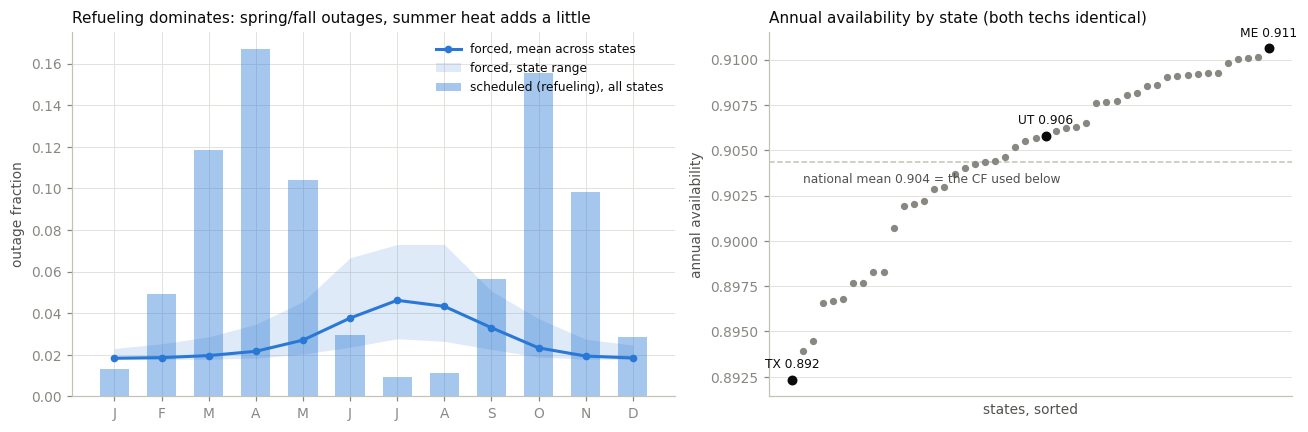

In [3]:
# Figure N1 -- what sets the availability ceiling, and how little it varies
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.15, 1]})

# (A) the two outage components across the year
ax = axes[0]
months = np.arange(1, 13)
sched_vals = sched_m.reindex(months).to_numpy()
fmon = forced_month                                   # per state, monthly mean
ax.bar(months, sched_vals, width=0.62,        # light tint of the shared large/blue hue:
       color=ps.ACCENT["blue"], alpha=0.42,   # ACCENT["blue"] at ~42% over SURFACE ≈ old #a9c7ec
       edgecolor="none", label="scheduled (refueling), all states")
ax.plot(months, fmon.mean(axis=1), color=COL["large"], lw=2, marker="o", ms=4,
        label="forced, mean across states")
ax.fill_between(months, fmon.min(axis=1), fmon.max(axis=1), color=COL["large"],
                alpha=0.15, lw=0, label="forced, state range")
ax.set_xticks(months)
ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_ylabel("outage fraction")
ax.set_title("Refueling dominates: spring/fall outages, summer heat adds a little",
             fontsize=10)
ax.legend(fontsize=8)

# (B) annual availability by state -- the whole spread is ~2 points
ax = axes[1]
s = avail_state.sort_values()
xpos = np.arange(len(s))
ax.scatter(xpos, s.to_numpy(), s=14, color=FAINT, zorder=3)
for st, c in [("TX", INK), ("UT", INK), ("ME", INK)]:
    i = int(np.where(s.index == st)[0][0])
    ax.scatter([i], [s[st]], s=30, color=c, zorder=4)
    ax.annotate(f"{st} {s[st]:.3f}", (i, s[st]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8, color=INK)
ax.axhline(CF, color=EDGE_C, lw=1, ls="--")
ax.annotate(f"national mean {CF:.3f} = the CF used below", (1, CF),
            textcoords="offset points", xytext=(0, -14), fontsize=8, color=MUTED)
ax.set_xticks([])
ax.set_xlabel("states, sorted")
ax.set_ylabel("annual availability")
ax.set_title("Annual availability by state (both techs identical)", fontsize=10)
fig.tight_layout()
plt.show()

**QA-A — the replication is ReEDS's own.** A materialized ReEDS run (`utshake_ut_learn`, a Utah-only
shakedown run) carries the representative-period outage tables that the ReEDS solve reads. This cell rebuilds
those tables for Utah from the hourly temperatures of weather year 2012 and asserts that every nuclear row
matches. It also shows that the representative-period averaging moves the annual availability by only about
3 × 10⁻⁴.

In [4]:
# QA-A -- the replication reproduces ReEDS's own pipeline outputs EXACTLY.
# A materialized run (utshake_ut_learn) carries the rep-period outage tables that
# 2_temporal_params.gms actually reads; rebuild them from our hourly series and compare.
# The run's tables are frozen in data/reeds_inputs/ (nuclear rows only; see its README).
hmap = pd.read_csv(RUN_SLICE / "utshake_hmap_myr.csv")
ts = pd.DatetimeIndex(pd.to_datetime(hmap["*timestamp"])).tz_convert(TZ_OUT)
hkey = hmap["h"].to_numpy()

# Utah's hourly temperatures, weather year 2012 (the run's weather year), local time Etc/GMT+6
ut = pd.read_csv(RUN_SLICE / "temperature_ut_2012_hourly.csv")
ut_idx = pd.DatetimeIndex(pd.to_datetime(ut["timestamp"])).tz_convert(TZ_OUT)
forced_ut = pd.Series(curve.to_numpy()[ut["deg_c"].to_numpy() - TEMP_MIN].astype(np.float32), index=ut_idx)
sched_ut = pd.Series(ut_idx.month.map(sched_m).to_numpy(), index=ut_idx)

# forced: (i,r,h) -- mean over each rep chunk's hours, rounded to 3 (hourly_writetimeseries.py)
back_f = pd.read_csv(RUN_SLICE / "utshake_outage_forced_h_nuclear.csv")
back_f.columns = ["i", "r", "h", "rate"]
mine_f = forced_ut.astype(float).reindex(ts).groupby(hkey).mean().round(3)
for tech in ["nuclear", "nuclear-smr"]:
    got = back_f.query("i == @tech and r == 'UT'").set_index("h")["rate"]
    assert len(got) > 0 and np.allclose(mine_f.reindex(got.index), got), tech

# scheduled: (i,h)
back_s = pd.read_csv(RUN_SLICE / "utshake_outage_scheduled_h_nuclear.csv")
back_s.columns = ["i", "h", "rate"]
mine_s = sched_ut.reindex(ts).groupby(hkey).mean().round(3)
for tech in ["nuclear", "nuclear-smr"]:
    got = back_s.query("i == @tech").set_index("h")["rate"]
    assert len(got) > 0 and np.allclose(mine_s.reindex(got.index), got), tech

# annual avail as GAMS sees it: avail(h) rounded to 3, weighted by hours(h)  (gms lines 381+906)
hours = pd.read_csv(RUN_SLICE / "utshake_numhours.csv")
hours.columns = ["h", "numhours"]
hours = hours.set_index("h")["numhours"]
avail_h = ((1 - mine_f) * (1 - mine_s)).round(3).reindex(hours.index)
avail_reeds_ut = float((avail_h * hours).sum() / hours.sum())
avail_8760_ut = float(avail_state["UT"])          # 15-year hourly mean for Utah
assert abs(avail_reeds_ut - avail_8760_ut) < 5e-4

print("QA-A PASSED: every nuclear/nuclear-smr row of the run's outage_forced_h.csv and")
print("  outage_scheduled_h.csv is reproduced exactly from the raw inputs (murphy2019 curve,")
print("  state temperatures, monthly refueling profile) -- the avail replication is ReEDS's own.")
print(f"  hours-weighted rep-period annual avail (UT): {avail_reeds_ut:.5f}"
      f"  vs plain 8760 mean: {avail_8760_ut:.5f}"
      f"  (difference {abs(avail_reeds_ut - avail_8760_ut):.1e} -- rep-period machinery"
      " is immaterial at annual resolution)")

QA-A PASSED: every nuclear/nuclear-smr row of the run's outage_forced_h.csv and
  outage_scheduled_h.csv is reproduced exactly from the raw inputs (murphy2019 curve,
  state temperatures, monthly refueling profile) -- the avail replication is ReEDS's own.
  hours-weighted rep-period annual avail (UT): 0.90547  vs plain 8760 mean: 0.90577  (difference 3.0e-04 -- rep-period machinery is immaterial at annual resolution)


### A2 — The operating-cost stack, tied to the cost dial

This cell prices the operating costs per kW of capacity. It reads the ATB 2024 advanced, moderate and
conservative rows for both technologies. It checks that the ATB advanced and conservative 2030 capital costs
equal the Monte Carlo anchor-cost range exactly, so one percentile `U1` indexes the whole ATB scenario axis.
It converts the AEO 2026 uranium price from 2025 to 2022 dollars (the Monte Carlo's dollar year). It levelizes
everything with ReEDS's 30-year factor and asserts that factor against the run's `crf.csv`.

**How to read the table.** The sign of the operating-cost gap changes along the dial. In cheap samples
(`U1 ≈ 0`) SMRs have the lower FOM. In expensive samples (`U1 ≈ 1`) large reactors have the lower FOM
(204 vs 216 $/kW-yr), while VOM and fuel still favour SMRs. The net operating-cost advantage of SMRs therefore
shrinks as `U1` rises. All money here is in 2022 dollars, as in notebook 01.

In [5]:
Z = np.load(NPZ, allow_pickle=False)
YEARS = Z["years"]
DISC = Z["disc"]
SCHED_ORDER = [str(s) for s in Z["sched_order"]]
TOK = dict(zip(SCHED_ORDER, [str(t) for t in Z["scen_tokens"]]))
WCOLS = [str(c) for c in Z["world_columns"]]
TECHS = ["large", "smr"]
REP = "McKinsey GEP 2025"
META = json.loads(str(Z["meta_json"]))

# ReEDS system real discount rate, recovered from the MC's own discount vector
post = DISC[YEARS > 2031]
d_real = float(DISC[-1] / DISC[-2])
assert np.allclose(np.diff(np.log(post)), np.log(d_real)), "DISC is not constant-rate"
assert round(d_real, 4) == 1.0536, f"real discount rate {d_real} is not ReEDS's post-2026 rate 1.0536"
EVAL_YEARS = 30                                   # sys_eval_years = eval_period (both techs)
ks = np.arange(1, EVAL_YEARS + 1)
pvf = float((d_real ** -ks).sum())                # annual $ -> 30-yr PV  (= ReEDS pvf_onm)
crf_ours = 1.0 / pvf

# QA-B part 1: the 1/crf identity against the materialized run
crf_file = pd.read_csv(RUN_SLICE / "crf.csv")
crf_file.columns = ["t", "crf"]
crf_run = float(crf_file.set_index("t")["crf"].loc[crf_file["t"].max()])
assert abs(round(crf_ours, 5) - crf_run) < 1e-9, (crf_ours, crf_run)
print(f"QA-B (1/2) PASSED: sum of 30 years of discounting at d_real={d_real:.6f} gives"
      f" crf={crf_ours:.5f}, matching the run's crf.csv ({crf_run}); pvf_onm = 1/crf = {pvf:.4f}")

# --- ATB 2024 plant characteristics: the O&M ranges and the capcost consistency check ---
def atb_row(tech, scen):
    f = REEDS_IN / f"plant_characteristics/{tech}_ATB_2024_{scen}.csv"
    return pd.read_csv(f).set_index("t").loc[2030]

ATB = {t: {s: atb_row({"large": "nuclear", "smr": "nuclear-smr"}[t], s)
           for s in ["advanced", "moderate", "conservative"]} for t in TECHS}

# the MC's anchor-cost ranges ARE the ATB advanced/conservative 2030 capcosts
BOAK_RANGE = {"large": (5250.0, 7750.0), "smr": (5500.0, 10000.0)}
for t in TECHS:
    assert (ATB[t]["advanced"]["capcost"], ATB[t]["conservative"]["capcost"]) == BOAK_RANGE[t]

OM = {t: {"fom": (float(ATB[t]["advanced"]["fom"]), float(ATB[t]["conservative"]["fom"])),
          "vom": (float(ATB[t]["advanced"]["vom"]), float(ATB[t]["conservative"]["vom"])),
          "hr": float(ATB[t]["moderate"]["heatrate"])} for t in TECHS}
for t in TECHS:   # heat rate is scenario-invariant
    assert len({float(ATB[t][s]["heatrate"]) for s in ATB[t]}) == 1

def om_at(tech, U1):
    """FOM ($/kW-yr) and VOM ($/MWh) at cost-dial percentile U1 (advanced -> conservative)."""
    lo_f, hi_f = OM[tech]["fom"]
    lo_v, hi_v = OM[tech]["vom"]
    return lo_f + U1 * (hi_f - lo_f), lo_v + U1 * (hi_v - lo_v)

# QA-B part 2: the convention's check values (SMR at U1 = 0.75)
f75, v75 = om_at("smr", 0.75)
b75 = 5500 + 0.75 * 4500
assert (round(f75, 1), round(v75, 2), b75) == (191.5, 2.65, 8875.0)
print("QA-B (2/2) PASSED: SMR at U1=0.75 -> boak $8,875/kW, FOM $191.5/kW-yr, VOM $2.65/MWh"
      " (the convention's check values); ATB advanced/conservative 2030 capcosts equal the"
      " MC anchor ranges exactly")

# --- uranium price: AEO 2026 baseline, 2025$ -> 2022$, flat after 2050 ---
defl = pd.read_csv(paths.deflator_path())
defl.columns = ["year", "deflator"]
defl = defl.set_index("year")["deflator"]                  # multiplier to 2004$
U2022 = float(defl.loc[2025] / defl.loc[2022])             # 2025$ -> 2022$
uran = pd.read_csv(REEDS_IN / "fuelprices/uranium_AEO_2026_baseline.csv").set_index("year")["cost"]
Pu = (uran * U2022).reindex(range(2024, int(YEARS.max()) + EVAL_YEARS + 1)).ffill()  # 2022$/MMBtu

# --- per-build-year fuel PV and the O&M NPV pieces (all 2022$/kW) ---
MWH_PER_KWYR = 8.760                                       # 8760 h/yr x CF -> MWh per kW-yr
def fuel_pv(tech, cf, ufac=1.0):
    """PV at build year t of 30 yrs of fuel, per kW: cf*8.76*HR * sum_k d^-k * Pu(t+k)."""
    out = np.zeros(len(YEARS))
    for j, t in enumerate(YEARS):
        out[j] = (Pu.loc[t + 1: t + EVAL_YEARS].to_numpy() * (d_real ** -ks)).sum()
    return cf * MWH_PER_KWYR * OM[tech]["hr"] * ufac * out

def om_npv(tech, U1, cf=CF, ufac=1.0):
    """(n_draws, n_years) 30-yr PV of FOM+VOM+fuel per kW of capacity built in each year."""
    fom, vom = om_at(tech, np.asarray(U1)[:, None])
    return pvf * (fom + cf * MWH_PER_KWYR * vom) + fuel_pv(tech, cf, ufac)[None, :]

# component table at the dial's ends and middle (per kW built in 2031)
j31 = int(np.where(YEARS == 2031)[0][0])
rows = []
for U1 in [0.0, 0.5, 1.0]:
    for t in TECHS:
        fom, vom = om_at(t, U1)
        fpv = float(fuel_pv(t, CF)[j31])
        rows.append({"U1": U1, "tech": t, "FOM $/kW-yr": round(fom, 1),
                     "VOM $/MWh": round(vom, 2),
                     "FOM PV $/kW": round(pvf * fom), "VOM PV $/kW": round(pvf * CF * MWH_PER_KWYR * vom),
                     "fuel PV $/kW": round(fpv),
                     "total $/kW": round(pvf * (fom + CF * MWH_PER_KWYR * vom) + fpv)})
comp = pd.DataFrame(rows).set_index(["U1", "tech"])
gap = comp["total $/kW"].unstack()
comp["gap (large - smr)"] = ""
for u in [0.0, 0.5, 1.0]:
    comp.loc[(u, "smr"), "gap (large - smr)"] = int(gap.loc[u, "large"] - gap.loc[u, "smr"])
print("\n30-yr PV of non-CAPEX costs per kW built in 2031 (2022$, CF = "
      f"{CF:.3f}, uranium AEO 2026 baseline):")
comp

QA-B (1/2) PASSED: sum of 30 years of discounting at d_real=1.053585 gives crf=0.06773, matching the run's crf.csv (0.06773); pvf_onm = 1/crf = 14.7637
QA-B (2/2) PASSED: SMR at U1=0.75 -> boak $8,875/kW, FOM $191.5/kW-yr, VOM $2.65/MWh (the convention's check values); ATB advanced/conservative 2030 capcosts equal the MC anchor ranges exactly

30-yr PV of non-CAPEX costs per kW built in 2031 (2022$, CF = 0.904, uranium AEO 2026 baseline):


FOM $/kW-yr  VOM $/MWh  FOM PV $/kW  VOM PV $/kW  fuel PV $/kW  \
U1  tech                                                                    
0.0 large        126.0       1.90         1860          222           557   
    smr          118.0       2.20         1742          257           487   
0.5 large        165.0       2.65         2436          310           557   
    smr          167.0       2.50         2466          292           487   
1.0 large        204.0       3.40         3012          398           557   
    smr          216.0       2.80         3189          327           487   

           total $/kW gap (large - smr)  
U1  tech                                 
0.0 large        2639                    
    smr          2486               153  
0.5 large        3303                    
    smr          3245                58  
1.0 large        3966                    
    smr          4003               -37

### A3 — The NPV ranking

This cell rebuilds the Monte Carlo's program-cost ranking with the full NPV in place of financed capital cost:
`R_npv = Σ_t (fincapex_t + OM_NPV_t) · w_t`, with the same schedule weights `w_t = GW_additions_t / disc_t`
that notebook 01 uses. Two checks run first. The capital-cost side must reproduce notebook 01's exported
program costs `R` and winner labels exactly. The operating-cost add-on must be exactly affine in `U1`, which
shows that the add-on introduces no new random content.

**How to read it.** The per-sample frame gains `R_npv`, `m_pct_npv` and `winner_npv` next to the capital-only
columns. Only the cost object changed; the margin definition and the tie rule did not.

In [6]:
D = {}
qa_aff_max = 0.0
for sched in SCHED_ORDER:
    tok = TOK[sched]
    w_t = Z[f"gw_additions_{tok}"] / DISC
    Wsum = float(w_t.sum())
    world = pd.DataFrame(Z[f"worlds_{tok}"], columns=WCOLS)
    d = pd.DataFrame({
        "U0": (world["lr_large"] - 0.03) / 0.09,
        "U1": (world["boak_large"] - 5250.0) / 2500.0,
        "conv_full": world["conv_full"].astype(int),
    })
    # comonotone-dial identities (same asserts as winner_boundary)
    assert np.allclose(world["lr_smr"], 0.03 + 0.13 * d["U0"])
    assert np.allclose(world["boak_smr"], 5500.0 + 4500.0 * d["U1"])

    for t in TECHS:
        R_cap = Z[f"fincapex_{tok}_{t}"] @ w_t
        assert np.allclose(R_cap, Z[f"R_{tok}_{t}"], rtol=1e-12), (sched, t)
        add = om_npv(t, d["U1"].to_numpy()) @ w_t
        # affine-in-U1 identity: the add-on is a straight line in U1 (fuel = intercept shift)
        a0 = om_npv(t, np.array([0.0])) @ w_t
        a1 = om_npv(t, np.array([1.0])) @ w_t
        qa_aff_max = max(qa_aff_max, float(np.abs(a0 + (a1 - a0) * d["U1"].to_numpy() - add).max()
                                           / Wsum))
        d[f"R_capex_{t}"] = R_cap
        d[f"R_npv_{t}"] = R_cap + add
        d[f"OMbar_{t}"] = add / Wsum                     # program-average $/kW of non-CAPEX
    for m in ["capex", "npv"]:
        rl, rs = d[f"R_{m}_large"], d[f"R_{m}_smr"]
        d[f"m_pct_{m}"] = 200.0 * (rl - rs) / (rl + rs)
        d[f"winner_{m}"] = np.where(rl <= rs, "large", "smr")   # ties -> large, as in the MC
        d[f"mbar_usd_{m}"] = (rl - rs) / Wsum
    assert (d["winner_capex"] == Z[f"winners_{tok}"].astype(str)).all(), sched
    D[sched] = d

assert qa_aff_max < 1e-9
print("QA-C PASSED: CAPEX-only ranking reproduces the MC's exported R arrays (rtol 1e-12) and")
print("  winner labels draw-for-draw on all six schedules; the NPV add-on is exactly affine in")
print(f"  U1 (max deviation {qa_aff_max:.1e} $/kW) -- no new stochastic content, ties -> large.")
ex = D[REP][["U0", "U1", "m_pct_capex", "m_pct_npv", "winner_capex", "winner_npv",
             "OMbar_large", "OMbar_smr"]].head(6).round(3)
print(f"\nmaster frame, first draws ({REP}):")
ex

QA-C PASSED: CAPEX-only ranking reproduces the MC's exported R arrays (rtol 1e-12) and
  winner labels draw-for-draw on all six schedules; the NPV add-on is exactly affine in
  U1 (max deviation 2.9e-12 $/kW) -- no new stochastic content, ties -> large.

master frame, first draws (McKinsey GEP 2025):


,U0,U1,m_pct_capex,m_pct_npv,winner_capex,winner_npv,OMbar_large,OMbar_smr
0,0.305,0.247,11.544,9.252,smr,smr,2945.534,2842.278
1,0.775,0.305,26.399,18.190,smr,smr,3023.074,2930.921
2,0.470,0.495,20.409,15.192,smr,smr,3274.204,3218.008
3,0.228,0.256,15.369,12.083,smr,smr,2957.251,2855.672
4,0.038,0.719,-3.264,-2.294,large,large,3572.288,3558.773
5,0.474,0.141,37.038,27.866,smr,smr,2805.352,2682.024


### A4 — Does the cheaper program change?

This cell counts the flips in each target trajectory and in each direction. It records where the flipped
samples sit: a sample can flip only if its capital-cost margin is smaller than its operating-cost gap, so the
flips should lie inside the close-call band `|m| < 2 %`. It also re-runs the P5/P50/P95 selection of the
100 %-SMR cases (notebook 04 selects the ReEDS production cases this way) with and without operating costs.

**How to read it.** In the table, `P(smr)` barely moves between the two rankings. Every flip starts inside the
2 % band. The selection check shows that the NPV ranking picks different individual samples at every
percentile, but that the swapped samples' SMR cost trajectories differ only modestly. This check is why the
case selection in notebook 04 ranks on the full NPV.

In [7]:
EPS_CLOSE = 2.0     # winner_boundary's close-call band, |m_pct| < 2%
rows, flips_all = [], []
for sched in SCHED_ORDER:
    d = D[sched]
    fl = d.index[(d["winner_capex"] == "large") & (d["winner_npv"] == "smr")]
    fs = d.index[(d["winner_capex"] == "smr") & (d["winner_npv"] == "large")]
    flipped = d.loc[fl.union(fs)]
    rows.append({
        "schedule": sched,
        "P(smr) capex": (d["winner_capex"] == "smr").mean(),
        "P(smr) npv": (d["winner_npv"] == "smr").mean(),
        "flips large->smr": len(fl), "flips smr->large": len(fs),
        "max |m_pct| among flips": float(flipped["m_pct_capex"].abs().max()) if len(flipped) else 0.0,
        "flips inside 2% band": float((flipped["m_pct_capex"].abs() < EPS_CLOSE).mean())
                                if len(flipped) else np.nan,
        "median OM gap $/kW": float((d["OMbar_large"] - d["OMbar_smr"]).median()),
    })
    for i in fl:
        flips_all.append({"schedule": sched, "draw": int(i), "direction": "large->smr"})
    for i in fs:
        flips_all.append({"schedule": sched, "draw": int(i), "direction": "smr->large"})
flips_all = pd.DataFrame(flips_all)
N4_TABLE = pd.DataFrame(rows).set_index("schedule")

# --- the 100%-SMR export's case selection under the NPV ranking -------------------
# smr100_case_export.ipynb ranks draws by R_smr (same weights) and takes p05/p50/p95;
# its fincapex_smr equals the npz's (QA-0 there). Re-rank with O&M added.
PCTS = [("p05", 0.05), ("p50", 0.50), ("p95", 0.95)]
sel_rows = []
for sched in SCHED_ORDER:
    d = D[sched]
    n = len(d)
    for name, R in [("capex", d["R_capex_smr"]), ("npv", d["R_npv_smr"])]:
        order = np.argsort(R.to_numpy())
        for pname, q in PCTS:
            sel_rows.append({"schedule": sched, "ranking": name, "pct": pname,
                             "draw": int(order[int(round(q * (n - 1)))])})
sel = (pd.DataFrame(sel_rows)
       .pivot_table(index=["schedule", "pct"], columns="ranking", values="draw", aggfunc="first")
       .astype(int))
sel["same draw"] = sel["capex"] == sel["npv"]
changed = sel.index[~sel["same draw"]]
traj_delta = []
for sched, pname in changed:
    tok = TOK[sched]
    d_old = int(sel.loc[(sched, pname), "capex"])
    d_new = int(sel.loc[(sched, pname), "npv"])
    fc = Z[f"fincapex_{tok}_smr"]
    live = Z[f"gw_additions_{tok}"] > 0
    rel = np.abs(fc[d_new, live] / fc[d_old, live] - 1.0)
    traj_delta.append({"schedule": sched, "pct": pname,
                       "median traj delta": float(np.median(rel)),
                       "max traj delta": float(rel.max())})
traj_delta = pd.DataFrame(traj_delta)

n_ls = int(N4_TABLE["flips large->smr"].sum())
n_sl = int(N4_TABLE["flips smr->large"].sum())
print(f"flips across all {6 * len(D[REP]):,} draws: {n_ls} large->smr, {n_sl} smr->large"
      f"  ({(n_ls + n_sl) / (6 * len(D[REP])):.2%} of draws)")
print(f"  every flip starts inside the 2% close-call band:"
      f" {bool((N4_TABLE['flips inside 2% band'].dropna() == 1.0).all())}"
      f"  (largest CAPEX margin among flips: "
      f"{N4_TABLE['max |m_pct| among flips'].max():.2f}%)")
print(f"smr100 case selection: {int(sel['same draw'].sum())}/18 selected draws unchanged"
      " under the NPV ranking")
if len(traj_delta):
    print("  changed selections and how different the swapped-in draw's SMR trajectory is:")
    print(traj_delta.to_string(index=False,
                               formatters={c: "{:.2%}".format for c in
                                           ["median traj delta", "max traj delta"]}))
N4_TABLE.round({"P(smr) capex": 4, "P(smr) npv": 4, "max |m_pct| among flips": 2,
                "flips inside 2% band": 2, "median OM gap $/kW": 0})

flips across all 60,000 draws: 280 large->smr, 119 smr->large  (0.66% of draws)


  every flip starts inside the 2% close-call band: True  (largest CAPEX margin among flips: 1.31%)
smr100 case selection: 0/18 selected draws unchanged under the NPV ranking
  changed selections and how different the swapped-in draw's SMR trajectory is:
             schedule pct median traj delta max traj delta
              2025 EO p05             4.53%          7.60%
              2025 EO p50            10.38%         19.92%
              2025 EO p95             0.84%          6.71%
      Abou-Jaoude mod p05             3.99%          5.56%
      Abou-Jaoude mod p50             5.82%         11.73%
      Abou-Jaoude mod p95             1.27%          3.86%
COP28 tripling pledge p05             3.23%         14.09%
COP28 tripling pledge p50             4.52%          8.75%
COP28 tripling pledge p95             0.62%          4.54%
    EIA 2026 AEO high p05             7.96%         11.23%
    EIA 2026 AEO high p50             1.95%          2.05%
    EIA 2026 AEO high p95             

,P(smr) capex,P(smr) npv,flips large->smr,flips smr->large,max |m_pct| among flips,flips inside 2% band,median OM gap $/kW
schedule,,,,,,,
EIA 2026 AEO high,0.8186,0.8209,50,27,0.69,1.0,56.0
Abou-Jaoude mod,0.8541,0.8561,44,24,0.81,1.0,55.0
IAEA high,0.8629,0.8658,47,18,0.91,1.0,56.0
McKinsey GEP 2025,0.8669,0.8700,49,18,1.01,1.0,54.0
COP28 tripling pledge,0.8776,0.8809,48,15,1.27,1.0,56.0
2025 EO,0.8865,0.8890,42,17,1.31,1.0,55.0


**Figure (diagnostic, not a paper item).** (a) The NPV margin against the capital-only margin for the McKinsey
target trajectory; every sample sits near the diagonal, and the flips (large dots) start next to zero.
(b) The flips on the two copula dials (`U0` = learning-rate dial, `U1` = cost dial), with the capital-only and
NPV flip boundaries. The flips trace the boundary band.

saved -> z-ethan\results\exports\03a\np_npv_margin_scatter.png


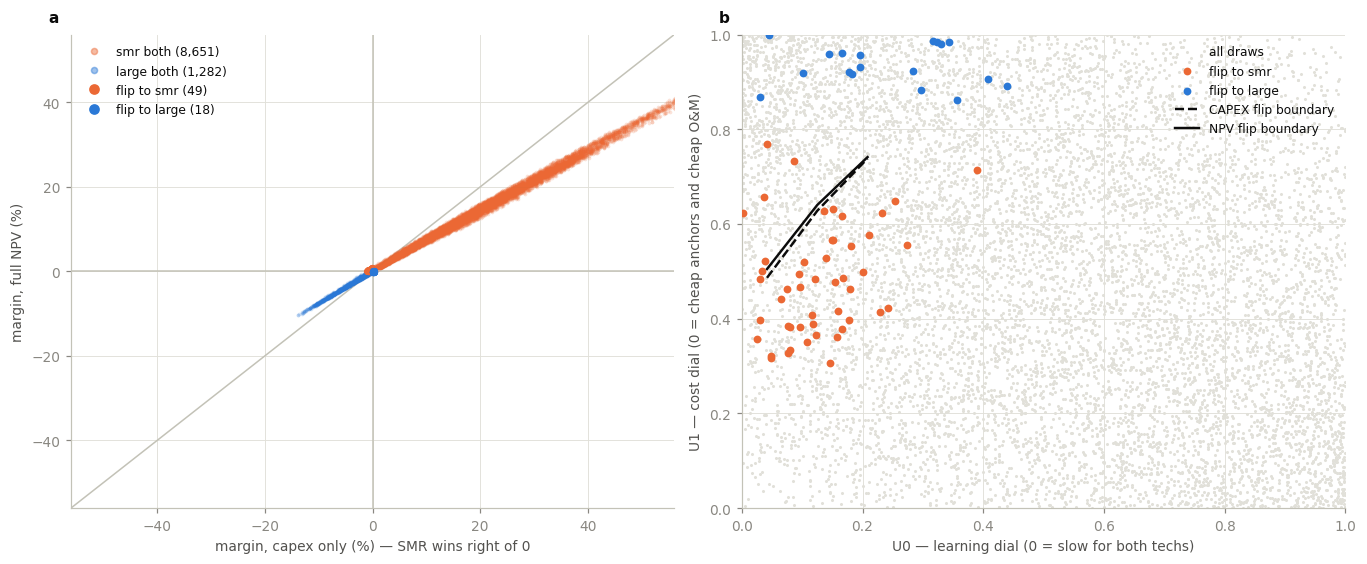

In [8]:
# Figures N4 -- margins barely move; the movers hug the old boundary
d = D[REP]
cls = np.select(
    [(d["winner_capex"] == "smr") & (d["winner_npv"] == "smr"),
     (d["winner_capex"] == "large") & (d["winner_npv"] == "large"),
     (d["winner_capex"] == "large") & (d["winner_npv"] == "smr"),
     (d["winner_capex"] == "smr") & (d["winner_npv"] == "large")],
    ["smr both", "large both", "flip to smr", "flip to large"])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))

# (A) margin vs margin: the NPV is a gentle, U1-dependent shift of the CAPEX margin
ax = axes[0]
from matplotlib.lines import Line2D
handles = []
for name, color, alpha, size, z in [
        ("smr both", COL["smr"], 0.18, 6, 2), ("large both", COL["large"], 0.18, 6, 2),
        ("flip to smr", COL["smr"], 1.0, 22, 4), ("flip to large", COL["large"], 1.0, 22, 4)]:
    sel_ = cls == name
    ax.scatter(d.loc[sel_, "m_pct_capex"], d.loc[sel_, "m_pct_npv"], s=size, lw=0,
               color=color, alpha=alpha, zorder=z)
    handles.append(Line2D([], [], ls="", marker="o", color=color,
                          alpha=1.0 if z == 4 else 0.45, ms=6 if z == 4 else 4,
                          label=f"{name} ({int(sel_.sum()):,})"))
lim = np.nanpercentile(np.abs(d[["m_pct_capex", "m_pct_npv"]]), 99.5)
ax.plot([-lim, lim], [-lim, lim], color=EDGE_C, lw=1, zorder=1)
ax.axhline(0, color=EDGE_C, lw=1)
ax.axvline(0, color=EDGE_C, lw=1)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("margin, capex only (%) — SMR wins right of 0")
ax.set_ylabel("margin, full NPV (%)")
ax.legend(handles=handles, fontsize=8, loc="upper left")

# (B) where the flips live on the two dials, against both flip boundaries
def boundary(dd, mcol, n0=12, n1=10):
    """zero-crossing of binned-median margin along U1, per U0 bin."""
    b0 = np.linspace(0, 1, n0 + 1)
    b1 = np.linspace(0, 1, n1 + 1)
    c1 = 0.5 * (b1[:-1] + b1[1:])
    xs, ys = [], []
    for j in range(n0):
        s = dd[(dd["U0"] >= b0[j]) & (dd["U0"] < b0[j + 1])]
        if len(s) < 100:
            continue
        med = s.groupby(pd.cut(s["U1"], b1, labels=False))[mcol].median()
        med = med.reindex(range(n1)).interpolate(limit_direction="both").to_numpy()
        sign = np.sign(med)
        cross = np.where(np.diff(sign) != 0)[0]
        if len(cross) == 0:
            continue
        i = cross[-1]
        frac = med[i] / (med[i] - med[i + 1])
        xs.append(0.5 * (b0[j] + b0[j + 1]))
        ys.append(c1[i] + frac * (c1[i + 1] - c1[i]))
    return np.array(xs), np.array(ys)

ax = axes[1]
ax.scatter(d["U0"], d["U1"], s=4, color=GRID_C, lw=0, zorder=1, label="all draws")
for name, color in [("flip to smr", COL["smr"]), ("flip to large", COL["large"])]:
    sel_ = cls == name
    if sel_.any():
        ax.scatter(d.loc[sel_, "U0"], d.loc[sel_, "U1"], s=26, color=color, lw=0, zorder=4,
                   label=name)
for mcol, ls, lab in [("m_pct_capex", "--", "CAPEX flip boundary"),
                      ("m_pct_npv", "-", "NPV flip boundary")]:
    bx, by = boundary(d, mcol)
    if len(bx):
        ax.plot(bx, by, color=INK, ls=ls, lw=1.6, zorder=3, label=lab)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("U0 — learning dial (0 = slow for both techs)")
ax.set_ylabel("U1 — cost dial (0 = cheap anchors and cheap O&M)")
ax.legend(fontsize=8, loc="upper right")
ps.letter_panels(axes)
fig.tight_layout()
ps.savefig(fig, FIGURES / "np_npv_margin_scatter.png")
plt.show()

### A5 — Robustness to the two judgement calls

The notebook fixed two inputs by judgement: which availability to use, and the uranium price path. This cell
recomputes the NPV win probability and the flip counts at the state availability extremes (Texas 0.892 and
Maine 0.911 instead of the 0.904 national mean) and at uranium prices ±50 %. O&M is not re-varied, because the
cost dial already spans the ATB range inside the Monte Carlo.

**How to read it.** The CF enters both technologies identically, so it only rescales the VOM and fuel part of
the gap. Uranium ±50 % moves the only term where the technologies genuinely differ (heat rate). If `P(smr)` and
the flip counts barely move across all nine combinations, neither judgement call changes the conclusion.

In [9]:
sens_rows = []
for cf_name, cf in [("CF lo (TX)", CF_STATE["lo (TX)"]), ("CF national", CF),
                    ("CF hi (ME)", CF_STATE["hi (ME)"])]:
    for u_name, ufac in [("uranium -50%", 0.5), ("uranium base", 1.0), ("uranium +50%", 1.5)]:
        psmr, nfl_ls, nfl_sl = [], 0, 0
        for sched in SCHED_ORDER:
            dd = D[sched]
            tok = TOK[sched]
            w_t = Z[f"gw_additions_{tok}"] / DISC
            Rn = {t: dd[f"R_capex_{t}"].to_numpy()
                     + om_npv(t, dd["U1"].to_numpy(), cf=cf, ufac=ufac) @ w_t
                  for t in TECHS}
            win = np.where(Rn["large"] <= Rn["smr"], "large", "smr")
            psmr.append((win == "smr").mean())
            nfl_ls += int(((dd["winner_capex"] == "large") & (win == "smr")).sum())
            nfl_sl += int(((dd["winner_capex"] == "smr") & (win == "large")).sum())
        sens_rows.append({"CF": cf_name, "uranium": u_name,
                          "P(smr) min..max": f"{min(psmr):.3f} .. {max(psmr):.3f}",
                          "flips large->smr": nfl_ls, "flips smr->large": nfl_sl})
SENS = pd.DataFrame(sens_rows).set_index(["CF", "uranium"])
print("NPV winner across availability and uranium settings (all six schedules pooled;")
print(" P(smr) range shown across schedules):")
SENS

NPV winner across availability and uranium settings (all six schedules pooled;
 P(smr) range shown across schedules):


P(smr) min..max  flips large->smr  flips smr->large
CF          uranium                                                         
CF lo (TX)  uranium -50%  0.814 .. 0.884                94               326
            uranium base  0.820 .. 0.889               272               130
            uranium +50%  0.830 .. 0.894               553                 8
CF national uranium -50%  0.814 .. 0.884                98               321
            uranium base  0.821 .. 0.889               280               119
            uranium +50%  0.830 .. 0.894               570                 5
CF hi (ME)  uranium -50%  0.814 .. 0.884                99               316
            uranium base  0.821 .. 0.889               284               115
            uranium +50%  0.831 .. 0.895               578                 2

### A6 — Evidence summary and exports

This cell prints the headline numbers and writes the two exports. `npv_winner_summary.csv` holds one row per
target trajectory: the CF, `P(smr)` under both rankings, the flip counts, and the median operating-cost gap.
`npv_flips.csv` lists every flipped sample with its dials and both margins. Notebook 03b reads both files.

In [10]:
# Evidence summary + exports
pooled_capex = float(np.mean([(D[s]["winner_capex"] == "smr").mean() for s in SCHED_ORDER]))
pooled_npv = float(np.mean([(D[s]["winner_npv"] == "smr").mean() for s in SCHED_ORDER]))
gap_med = float(np.median(np.concatenate(
    [(D[s]["OMbar_large"] - D[s]["OMbar_smr"]).to_numpy() for s in SCHED_ORDER])))
gap_rng = [float(np.percentile(np.concatenate(
    [(D[s]["OMbar_large"] - D[s]["OMbar_smr"]).to_numpy() for s in SCHED_ORDER]), q))
    for q in (5, 95)]
n_flips = n_ls + n_sl

print("=" * 78)
print("EVIDENCE SUMMARY -- NPV winner check")
print("=" * 78)
print(f"1. CF used (ReEDS avail, both techs identical): {CF:.3f}"
      f"  [state range {CF_STATE['lo (TX)']:.3f}-{CF_STATE['hi (ME)']:.3f}]")
print(f"2. non-CAPEX gap, program-average (large - smr): median ${gap_med:,.0f}/kW"
      f"  [p5-p95: ${gap_rng[0]:,.0f} .. ${gap_rng[1]:,.0f}]"
      "  -- positive = favors SMR")
print(f"3. P(SMR wins), mean across schedules: {pooled_capex:.3f} (CAPEX) -> {pooled_npv:.3f} (NPV)")
in_band = N4_TABLE["flips inside 2% band"].dropna()
band_txt = ("all inside the 2% close-call band" if bool((in_band == 1.0).all())
            else f"{float(in_band.mean()):.0%} inside the 2% close-call band")
print(f"4. flips: {n_ls} large->smr, {n_sl} smr->large  ="
      f" {n_flips / (6 * len(D[REP])):.2%} of all draws; {band_txt}")
n_same = int(sel["same draw"].sum())
td = (f" (trajectory deltas of the swapped draws: median {traj_delta['median traj delta'].median():.1%},"
      f" max {traj_delta['max traj delta'].max():.1%})" if len(traj_delta) else "")
print(f"5. smr100 export selection: {18 - n_same}/18 draw identities change under NPV ranking{td}")
print("=" * 78)

summary = N4_TABLE.copy()
summary.insert(0, "CF", CF)
summary.to_csv(EXPORTS / "npv_winner_summary.csv")
if len(flips_all):
    fl_rows = []
    for _, r in flips_all.iterrows():
        dd = D[r["schedule"]].loc[r["draw"]]
        fl_rows.append({**r, "U0": dd["U0"], "U1": dd["U1"], "conv_full": int(dd["conv_full"]),
                        "m_pct_capex": dd["m_pct_capex"], "m_pct_npv": dd["m_pct_npv"]})
    pd.DataFrame(fl_rows).round(4).to_csv(EXPORTS / "npv_flips.csv", index=False)
else:
    pd.DataFrame(columns=["schedule", "draw", "direction", "U0", "U1", "conv_full",
                          "m_pct_capex", "m_pct_npv"]).to_csv(EXPORTS / "npv_flips.csv",
                                                              index=False)
print(f"wrote {paths.rel(EXPORTS / 'npv_winner_summary.csv')}")
print(f"wrote {paths.rel(EXPORTS / 'npv_flips.csv')}")

EVIDENCE SUMMARY -- NPV winner check
1. CF used (ReEDS avail, both techs identical): 0.904  [state range 0.892-0.911]
2. non-CAPEX gap, program-average (large - smr): median $55/kW  [p5-p95: $-30 .. $141]  -- positive = favors SMR
3. P(SMR wins), mean across schedules: 0.861 (CAPEX) -> 0.864 (NPV)
4. flips: 280 large->smr, 119 smr->large  = 0.66% of all draws; all inside the 2% close-call band
5. smr100 export selection: 18/18 draw identities change under NPV ranking (trajectory deltas of the swapped draws: median 2.6%, max 21.6%)
wrote z-ethan\results\exports\03a\npv_winner_summary.csv
wrote z-ethan\results\exports\03a\npv_flips.csv


### What Section A does and does not establish

**Established.** Under ReEDS's own availability, ReEDS's own O&M and fuel inputs tied to the sample's cost
percentile, and ReEDS's own 30-year levelization, the full-NPV ranking reproduces the capital-only winner in
more than 99 % of samples. The exceptions are samples that were near-ties to begin with, and the flip boundary
in the two-dial plane barely moves. Ranking the pure programs on financed capital cost is therefore safe.

**One genuine sensitivity.** The *case selection* is less robust than the *winner*. Adding operating costs to
the SMR-program ranking changes which individual sample sits nearest each P5/P50/P95 target. The production
case selection (notebook 04) therefore ranks on the full NPV and writes each case's matching FOM and VOM into
the exported plant-characteristic files.

**Outside this section's assumptions.**
- *Dispatch asymmetry.* ReEDS enforces different minimum-generation floors (`mingen_fixed`: 0.7 large, 0.4 SMR).
  Realized capacity factors inside a ReEDS solve can therefore differ between the technologies, although
  `avail` cannot. CF = avail is a tech-neutral upper bound for a mandated build program.
- *Investment tax credit.* The ranking excludes the ITC, as notebook 01 does; the 30 % ITC applies to both
  technologies at the same fraction.

## Section B — Mixed-build optimizer: could any split of the program beat the better pure program?

Notebook 01 assumes *winner-take-all*: in each sample, the whole US build program goes to the cheaper
technology. Its fragmentation figure (Supplementary Figure 5f) shows that a 50/50 split always costs more.
The reason is learning by doing. Each technology's cost falls with its own cumulative builds, so splitting the
program splits the learning: each technology climbs only part of its learning curve, and both end up dearer
than the one technology would have been alone.

That result rests on two assumptions that work against mixing. This section relaxes both and then searches
actively for a winning mixed strategy.

1. **Cross-technology spillover.** Notebook 01's fragmentation experiment lets no experience cross between the
   technologies. Here each sample draws two spillover fractions, `x_ls` (large → SMR) and `x_sl` (SMR → large),
   each uniform on [0, 30 %]. With spillover, a switch strategy becomes conceivable: build the initially cheaper
   technology first, let its experience spill over, and switch once the other technology has come down its curve.
2. **Independent, ordered draws.** Notebook 01 draws both technologies' anchor costs at the same percentile of
   their ranges, and likewise their learning rates. Here each technology's (learning rate, anchor cost) pair is
   drawn independently, subject only to the two orderings that define the SMR proposition: the SMR starts dearer
   (`boak_smr > boak_large`) and learns faster (`lr_smr > lr_large`). The **anchor cost** (BOAK, best-of-a-kind)
   is the 2030 overnight cost of a technology. The cost gap and the learning-rate gap then vary freely.

For each sample, an optimizer chooses the SMR share of each build year, 2031–2050 (a 20-element profile), to
minimize the discounted financed cost of meeting that sample's deployment target. The two pure strategies are
always candidates. The headline quantity is the signed **margin** of the best genuinely mixed strategy over the
best pure strategy; a negative margin means mixing wins. All costs are conditional on the imposed deployment
target: they answer "what would it cost to build this much", not "what will be built".

The section keeps the source notebook's seeds: one master seed, 20260715, and independent named random streams
(`SeedSequence((20260715, crc32(label)))`, every label prefixed `mixopt/`). Its draws are therefore separate from
notebook 01's draws. Section B does not read `mc_perdraw.npz`.

In [11]:
import zlib

from scipy import stats
from scipy.optimize import minimize

# Port note: code comments in Section B call the Monte Carlo notebook (notebook 01) "the companion"
# or "mc" and cite its section numbers (S1-S13); the engine code itself is a verbatim port.
EXPORTS = EXP_DIR / "mixed_build"              # Section B's analysis exports
EXPORTS.mkdir(parents=True, exist_ok=True)
FIGURES = EXP_DIR                              # the SF5 panel sources

# --- Reproducibility: one master seed, independent named streams (same policy as the
# companion notebook; every stream name here is prefixed "mixopt/" so no stream can
# collide with the companion notebook's draws) ---
MASTER_SEED = 20260715
assert MASTER_SEED == 20260715, "the paper's Monte Carlo master seed is 20260715"

def rng_stream(name):
    """An independent, reproducible random generator tied to a label."""
    return np.random.default_rng(np.random.SeedSequence((MASTER_SEED, zlib.crc32(name.encode()))))

# --- Analysis switches ---
# The anchor-cost and learning-rate draws are INDEPENDENT between the technologies,
# conditioned on the two orderings every real SMR proposal respects (S4):
#   boak_smr > boak_large   (the SMR starts more expensive)
#   lr_smr   > lr_large     (the SMR learns faster)
# The companion notebook's comonotone (same-percentile) draw is retained only as the
# QA-G continuity limit.

# Cross-technology spillover: each simulated future draws two fractions uniformly on
# [0, X_SPILL_MAX] — how much of one technology's US build experience also teaches the
# other technology's vendors (large->SMR and SMR->large are drawn independently).
X_SPILL_MAX = 0.30

# The US historical large-reactor fleet does NOT flow to SMRs through the drawn spillover:
# the empirical SMR learning-rate range already embeds any benefit from those prior builds
# (the companion notebook's D8' convention). Only post-2030 program builds spill over.
HIST_CROSS_TECH = False

COPULA_SET = "moderate"                        # lr <-> boak correlation set (as companion)

# Optimizer-funnel controls (S6): a draw goes to the expensive free optimizer if any mixed
# candidate in the cheap vectorized screen comes within EPS_FLAG of the best pure corner;
# AUDIT_FRAC of draws are polished regardless, to verify the screen misses nothing.
EPS_FLAG = 0.005
AUDIT_FRAC = 0.03
TOL_WIN = 0.001          # a mixed strategy "wins" if it beats the best corner by > 0.1%

# Draw count per target trajectory (the paper's run: 10,000)
N_DRAWS_OPT = 10000
REP_SCHED = "McKinsey GEP 2025"                # representative schedule (worked example, QA)

# --- Model frame (identical to the companion notebook) ---
YEARS = np.arange(2024, 2051)
T = len(YEARS)
def yi(y):
    """Index of calendar year y in the YEARS grid."""
    return int(np.where(YEARS == y)[0][0])

ANCHOR = 2030
N_BOAK_UNITS = 2.0
OMEGA = 1.0 / 3.0
CES_RHO_GRID = np.array([-1.0, 0.0, 1.0])   # symmetric since 2026-08-06 (companion S1)
TECH = {
    "large": {"unit_gw": 1.000, "lr_lo": 0.03, "lr_hi": 0.12,
              "boak_lo": 5250.0, "boak_hi": 7750.0},
    "smr":   {"unit_gw": 0.300, "lr_lo": 0.03, "lr_hi": 0.16,
              "boak_lo": 5500.0, "boak_hi": 10000.0},
}
UNIT_FOREIGN_GW = 1.0
U_GRID = np.linspace(0.0, 1.0, 21)

# The optimizer's decision variable: SMR share of each build year 2031-2050
BUILD_YEARS = np.arange(2031, 2051)
N_P = len(BUILD_YEARS)                          # 20
BUILD_SLICE = slice(yi(2031), yi(2050) + 1)

print(f"exports      : {paths.rel(EXPORTS)}")
print(f"switches     : x_spill_max={X_SPILL_MAX}, copula={COPULA_SET}, "
      f"draws/schedule={N_DRAWS_OPT} (independent draws, ordered: SMR pricier, SMR faster-learning)")
print(f"funnel       : eps_flag={EPS_FLAG:.1%}, audit={AUDIT_FRAC:.0%}, win tolerance={TOL_WIN:.1%}")

exports      : z-ethan\results\exports\03a\mixed_build
switches     : x_spill_max=0.3, copula=moderate, draws/schedule=10000 (independent draws, ordered: SMR pricier, SMR faster-learning)
funnel       : eps_flag=0.5%, audit=3%, win tolerance=0.1%


## What is different from notebook 01 — and how to turn each change off

| Change | What it does | Why | "Off" setting |
|---|---|---|---|
| **Independent, ordered draws** | Anchor costs and learning rates are drawn independently between the technologies, conditioned on `boak_smr > boak_large` and `lr_smr > lr_large`. Published ranges are unchanged (truncated by the conditioning). | Notebook 01's same-percentile draw pinned both gaps to one dial; here the cost gap and the learning-rate gap vary freely — every draw is a genuine "pay more now, learn faster" SMR bet. | Notebook 01's comonotone draw is retained as the QA-G limit |
| **Cross-technology spillover** | Two drawn fractions `x_ls` (large→SMR) and `x_sl` (SMR→large), each U(0, 30%), feed one technology's post-2030 US builds into the other's discounted cross-firm learning channel. | The only mechanism by which "build cheap traditional first" could ever pay off. | Force both to 0 (the spillover sensitivity below does this) |
| **Optimizer instead of winner-take-all** | A per-future optimizer chooses the SMR share of every build year to minimize discounted financed program cost. | Tests *all* mixed strategies, not just 50/50. | The two pure strategies are always in the candidate set |

Everything else — the six deployment schedules, the PRIS-based international stocks, the
learning-curve engine, the construction-duration model, and the ReEDS financing replication —
is **ported unchanged** from notebook 01, and the QA cells at the end of this section assert that at the
"off" settings this notebook reproduces the notebook 01 engine bit-for-bit.

### B1 — The six deployment targets

The notebook reads the targets from `inputs/nuclear_learning/US_SCHEDULES.csv`, which notebook 01 writes and
the ReEDS mandate files use. Values are capacity indices (100 = the 97 GW fleet of 2024). The working GW basis
everywhere is the index read as GW minus a flat 3 GW, as in notebook 01 and the ReEDS mandate files.

In [12]:
US_GW_2024 = 97.0
OFFSET_GW = 3.0

US_SCHEDULES_CSV = REEDS_IN / "nuclear_learning" / "US_SCHEDULES.csv"
_sched_df = pd.read_csv(US_SCHEDULES_CSV, comment="#", index_col="year")

# Display names for the machine tokens in the CSV, in fixed ascending-ambition order
TOKEN_NAME = {"eia_aeo_high": "EIA 2026 AEO high", "abou_jaoude": "Abou-Jaoude mod",
              "iaea_high": "IAEA high", "mckinsey": "McKinsey GEP 2025",
              "cop28": "COP28 tripling pledge", "eo2025": "2025 EO"}
assert set(_sched_df.columns) == set(TOKEN_NAME), "US_SCHEDULES.csv columns changed"
assert list(_sched_df.index) == list(YEARS), "US_SCHEDULES.csv year grid changed"

US_SCHEDULES = {TOKEN_NAME[tok]: _sched_df[tok].to_numpy(float) for tok in TOKEN_NAME}
SCHED_ORDER = list(US_SCHEDULES)
SCEN_TOKEN = {v: k for k, v in TOKEN_NAME.items()}

print("schedules loaded (2050 capacity in working GW basis):")
for name in SCHED_ORDER:
    print(f"  {name:22s} {US_SCHEDULES[name][-1] - OFFSET_GW:5.0f} GW")

schedules loaded (2050 capacity in working GW basis):
  EIA 2026 AEO high        114 GW
  Abou-Jaoude mod          131 GW
  IAEA high                169 GW
  McKinsey GEP 2025        197 GW
  COP28 tripling pledge    297 GW
  2025 EO                  397 GW


### B2 — Historical and international experience

The learning engine needs the nuclear construction experience outside the US program. The IAEA PRIS reactor
database (via the RDS-2 2025 unit list) gives every unit ever grid-connected, the units under construction, and
region-by-region growth milestones. This part is a verbatim port of notebook 01; see its section on
international experience for the full explanation. The second cell also computes the quantity the optimizer
divides: the US gross GW added per year under each target after the 2030 anchor.

In [13]:
# Ported verbatim from notebook 01's engine (regional milestones, PRIS load,
# retirement identity, committed pipeline, historical stocks).
REGION_MILESTONES = {
    "CA":  (12.7, 12.7, 12.7, 18.8, 23.0, 30.0, 63.7),
    "SAM": (5.1, 5, 5, 8, 11, 8, 20),
    "WEU": (95.4, 86, 92, 81, 114, 68, 136),
    "EEU": (53.6, 57, 57, 58, 82, 68, 103),
    "AF":  (1.9, 4, 5, 7, 12, 12, 30),
    "WA":  (5.8, 11, 11, 12, 20, 15, 35),
    "SA":  (11.1, 18, 22, 25, 43, 45, 85),
    "CEA": (94.5, 136, 144, 215, 264, 242, 328),
    "SEA": (0, 0, 0, 3, 7, 4, 18),
    "OC":  (0, 0, 0, 0, 0, 0, 2),
}
THETA_KV = {"CA": 0.28, "SAM": 0.14, "WEU": 0.17794117647, "EEU": 0.1325, "AF": 0.16688725490,
            "WA": 0.13375, "SA": 0.185, "CEA": 0.135, "SEA": 0.16583333, "OC": 0.18}
REGIONS = list(THETA_KV.keys())

from nlpaper import pris_loader as pl

PRIS_UNITS = pl.load_units(str(pl.UNITS_CSV))      # inputs/nuclear_learning/rds2_2025_units.csv
_milestones_2024 = {r: REGION_MILESTONES[r][0] for r in REGIONS} | {"US": US_GW_2024}
_issues = pl.validate_units(PRIS_UNITS[PRIS_UNITS["status"] == "operational"], _milestones_2024)
assert not _issues, _issues

FLEET = PRIS_UNITS[PRIS_UNITS["status"] == "operational"]
UC_UNITS = PRIS_UNITS[PRIS_UNITS["status"] == "under construction"]

def retirement_flow_gw(key, life_yr):
    """GW retiring per model year, from each unit's real grid-connection date + a lifetime rule."""
    return pl.retirement_schedule(FLEET, pd.Index(YEARS), lifetime_years=life_yr,
                                  region=key).to_numpy()

PIPE_END = 2030   # pipeline's real visibility horizon; structurally zero after 2030 (mc S3)
PIPELINE_GW = {r: pl.committed_pipeline(UC_UNITS[UC_UNITS["region"] == r],
                                        pd.Index(np.arange(2025, PIPE_END + 1)),
                                        lead_time_months=72).to_dict()
               for r in REGIONS}

# Under-construction units are excluded: 5 carry PLANNED grid dates (not completed experience)
_ever = PRIS_UNITS[(PRIS_UNITS["status"] != "under construction")
                   & PRIS_UNITS["grid_connection"].notna()]
HIST_UNITS = {r: int((_ever["region"] == r).sum()) for r in REGIONS + ["US"]}

US_LICENSE_LIFE = 80.0
ONE_FACTOR_DELTA = 0.0

print(f"PRIS fleet loaded: {len(FLEET)} operational, {len(UC_UNITS)} under construction")

PRIS fleet loaded: 417 operational, 62 under construction


In [14]:
# Ported verbatim from companion S3: foreign stocks on the u grid, plus this notebook's
# per-schedule GROSS GW ADDITIONS (the quantity the optimizer splits between technologies).
def net_path_gw(region, u):
    """Regional net capacity path: interpolate the 2024/2030/2040/2050 milestones, positioned
    between Low and High by the global deployment draw u."""
    c = REGION_MILESTONES[region]
    vals = [c[0], c[1] + u*(c[2]-c[1]), c[3] + u*(c[4]-c[3]), c[5] + u*(c[6]-c[5])]
    return np.interp(YEARS, [2024, 2030, 2040, 2050], vals)

def gross_additions_gw(region, u):
    """The retirement identity: builds = max(0, capacity change + retirements); the committed
    pipeline REPLACES the interpolated path through PIPE_END = 2030 (real units; structurally
    zero after 2030, so it only shapes the pre-anchor record - see mc_cost_trajectories S3)."""
    dnet = np.diff(net_path_gw(region, u), prepend=net_path_gw(region, u)[0])
    ret = retirement_flow_gw(region, 65.0 + 5.0*u)   # IAEA-calibrated lives, 65+5u (mc S3; 2026-08-05)
    g = np.clip(dnet + ret, 0.0, None)
    pipe_mask = YEARS <= PIPE_END
    g[pipe_mask] = [PIPELINE_GW[region].get(int(y), 0.0) for y in YEARS[pipe_mask]]
    return g

# Foreign stocks on the u grid (companion S3): unsplit, 1-GW basis - the engine's cross-firm
# channel does not distinguish designs (companion S5 Step 5). The IAEA SMR-share split of the
# foreign fleet lives in the main notebook's S14 own-routing sensitivity, not in any engine.
REGION_STOCK = {}
for r in REGIONS:
    m_a = np.empty((len(U_GRID), T))
    for gi, u in enumerate(U_GRID):
        flow = gross_additions_gw(r, u)
        flow = flow.copy(); flow[YEARS <= ANCHOR] = 0.0
        m_a[gi] = np.cumsum(flow) / UNIT_FOREIGN_GW
    REGION_STOCK[r] = m_a

# US gross GW added per year under each schedule, counted from the 2030 anchor. This is the
# pie the optimizer divides: GW_ADD[sched][t] * p(t) goes to SMRs, the rest to large reactors.
US_RET = retirement_flow_gw("US", US_LICENSE_LIFE)
GW_ADD = {}
for name in SCHED_ORDER:
    cap = US_SCHEDULES[name] - OFFSET_GW
    dnet = np.diff(cap, prepend=cap[0])
    flow = np.clip(dnet + US_RET, 0.0, None)
    flow[YEARS <= ANCHOR] = 0.0
    GW_ADD[name] = flow

print("total post-2030 gross additions per schedule (GW):")
for name in SCHED_ORDER:
    print(f"  {name:22s} {GW_ADD[name].sum():6.1f} GW over {int((GW_ADD[name] > 0).sum())} build years")

total post-2030 gross additions per schedule (GW):
  EIA 2026 AEO high        20.7 GW over 15 build years
  Abou-Jaoude mod          36.4 GW over 20 build years
  IAEA high                75.7 GW over 20 build years
  McKinsey GEP 2025       103.4 GW over 20 build years
  COP28 tripling pledge   203.4 GW over 20 build years
  2025 EO                 303.4 GW over 20 build years


### B3 — The learning-curve engine, with cross-technology spillover

The engine is notebook 01's. Each technology's overnight capital cost falls as two experience stocks grow. The
**own** stock counts the vendor's own design (full learning rate). The **cross-firm** stock counts other vendors
and θ·s-weighted international builds, at ⅓ strength (`OMEGA`). The engine is anchored so that the 2030 cost
equals the drawn anchor cost exactly.

The cross-technology term adds a drawn fraction `x` of the *other* technology's domestic program to the
cross-firm stock:

$$A_B(t) \mathrel{+}= x \cdot N_A(t)$$

International experience stays in the cross-firm stock, unsplit between technologies, so `x` scales no foreign
term. The historical pre-2030 US fleet is excluded from the cross-technology channel (`HIST_CROSS_TECH = False`),
because the SMR learning-rate range already embeds it. With the cross-technology arguments off, the engine is
bit-for-bit notebook 01's (QA-A below).

In [15]:
H_ALL_W = sum(THETA_KV[r]*HIST_UNITS[r] for r in REGIONS)   # theta-weighted historical foreign stock

def lag1(a):
    """One-year completion lag along the time axis: the stock ENTERING year t is the builds
    completed through t-1. Cumulative arrays stay end-of-year for accounting; the lag is
    applied here, at the pricing boundary - without it the first post-anchor cohort would
    price on its own not-yet-built units (below BOAK). Companion-identical (mc S5)."""
    a = np.asarray(a, float)
    out = np.zeros_like(a)
    out[..., 1:] = a[..., :-1]
    return out

OTHER_TECH = {"large": "smr", "smr": "large"}
X_IN_COL = {"large": "x_sl", "smr": "x_ls"}     # incoming cross-tech fraction, per receiving tech

def intl_stock(world):
    """Theta-weighted foreign post-anchor stock, (n_draws, T), UNLAGGED. Unsplit across
    technologies: the engine's cross-firm channel does not distinguish designs (companion
    S5 Step 5). It depends only on the drawn global-deployment position u, so callers that
    evaluate many share profiles for the same worlds compute it once and pass it back in
    (the optimizer's hot loop)."""
    n = len(world)
    u_r = np.repeat(world["u"].values[:, None], len(REGIONS), axis=1)
    if ONE_FACTOR_DELTA > 0:
        u_r = np.clip(u_r + rng_stream("one_factor_noise").uniform(
            -ONE_FACTOR_DELTA, ONE_FACTOR_DELTA, (n, len(REGIONS))), 0, 1)
    gi = np.clip(np.rint(u_r * (len(U_GRID)-1)).astype(int), 0, len(U_GRID)-1)
    S = np.zeros((n, T))
    for j, r in enumerate(REGIONS):
        S += THETA_KV[r] * REGION_STOCK[r][gi[:, j], :]
    return S

def experience_channels(world, tech, n_us, n_oth=None, x_in=None, S_KV=None):
    """The two experience stocks O_d(t) (own) and A_d(t) (cross-firm), each (n_draws, T).
    Companion-identical math (mc S5): international experience enters the CROSS-FIRM
    channel at weight s*theta, unsplit across technologies (the K&V flows are normalized
    to the domestic inter-firm citation baseline - omega prices the firm wall, theta the
    border). Two hot-loop conveniences:
      x_in:  override for the incoming cross-tech fraction (scalar or (n_draws,)); None ->
             the drawn world column (x_sl into large, x_ls into SMR). Used by the x_zero
             sensitivity and QA.
      S_KV:  optional precomputed intl_stock(world) array (pure caching, no change in values).
    n_oth is the OTHER technology's cumulative post-anchor US units, (T,) or (n_draws, T).
    """
    n = len(world)
    if S_KV is None:
        S_KV = intl_stock(world)
    skv = lag1(S_KV)                                     # stock entering year t (built thru t-1)
    N_us = lag1(np.broadcast_to(np.asarray(n_us, float), (n, T)))
    conv = world["conv_full"].values[:, None].astype(float)
    m = world["n_vendors"].values[:, None].astype(float)
    s = world["s"].values[:, None]
    # US historical fleet counts toward LARGE only (companion D8'): crediting the ~140-unit
    # LWR stock to SMRs would double-count what the empirical SMR learning-rate range embeds.
    hist_us = HIST_UNITS["US"] if tech == "large" else 0.0
    own0 = N_BOAK_UNITS + conv*hist_us/m
    own = own0 + N_us/m
    oth = (m-1.0)*own0 + N_us*(m-1.0)/m \
          + s*(conv*H_ALL_W + skv)
    if n_oth is not None:
        x = np.asarray(world[X_IN_COL[tech]].values if x_in is None else x_in, float)
        if x.ndim == 1:
            x = x[:, None]
        N_oth = lag1(np.broadcast_to(np.asarray(n_oth, float), (n, T)))  # completed units only
        oth = oth + x * N_oth                            # the cross-technology spillover term
    return own, oth

CES_EPS = 1e-8

def occ_paths_ces(world, tech, n_us, n_oth=None, x_in=None, ces_rho=None, S_KV=None):
    """Production OCC engine (companion D11/D12, ported verbatim; the cross-tech/caching
    arguments just pass through to experience_channels). Returns $/kW (2022 USD), (n_draws, T)."""
    own, oth = experience_channels(world, tech, n_us, n_oth=n_oth, x_in=x_in, S_KV=S_KV)
    assert own.min() >= N_BOAK_UNITS and oth.min() >= N_BOAK_UNITS, "stock below anchor base; log unsafe"
    lr = world[f"lr_{tech}"].values[:, None]
    b1, b2 = np.log2(1.0 - lr), np.log2(1.0 - OMEGA*lr)
    b, w = -(b1 + b2), b1/(b1 + b2)
    rho = world["ces_rho"].values if ces_rho is None else np.full(len(world), float(ces_rho))
    rho = rho[:, None]
    geo = np.abs(rho) < CES_EPS
    lnO, lnA = np.log(own), np.log(oth)
    with np.errstate(over="raise"):
        lnE = np.where(geo, w*lnO + (1.0-w)*lnA,
                       lnO + np.log1p((1.0-w)*np.expm1(np.where(geo, 0.0, rho)*(lnA - lnO)))
                           / np.where(geo, 1.0, rho))
    return world[f"boak_{tech}"].values[:, None] * np.exp(-b*(lnE - lnE[:, [yi(ANCHOR)]]))

def percentile_table(paths, ps=(5, 25, 50, 75, 95)):
    """Yearly percentiles of a (n_draws, T) trajectory array."""
    return pd.DataFrame({f"P{p}": np.percentile(paths, p, axis=0) for p in ps}, index=YEARS)

### B4 — Construction durations and financing

Durations follow the INL series-reduction curves: each vendor's next project is faster. A technology's duration
responds only to its **own** builds; spillover lowers costs but never shortens the other technology's schedules.
Financing replicates ReEDS's overnight-to-financed multiplier, with interest during construction evaluated at
each sample's learned duration. Both parts are verbatim ports of notebook 01; QA-E re-pins the financing port to
the ReEDS learning engine's regression value.

In [16]:
# Ported verbatim from companion S6: PRIS duration panel -> residual dispersion sig_hat.
DUR_UNITS = pl.duration_panel(PRIS_UNITS)
DUR_UNITS = DUR_UNITS[DUR_UNITS["family"].isin(["AP1000", "APR1400", "HPR1000"])].reset_index(drop=True)
DUR_UNITS = DUR_UNITS.rename(columns={"reactor_name": "unit"})

def fit_family_fe(df):
    """ln(duration) = family intercepts + b*ln(family sequence); returns (coefficients, residual sd)."""
    X = np.column_stack([np.ones(len(df)),
                         (df["family"] == "APR1400").astype(float),
                         (df["family"] == "HPR1000").astype(float),
                         np.log(df["family_seq"].astype(float))])
    Y = np.log(df["months"].values)
    beta, *_ = np.linalg.lstsq(X, Y, rcond=None)
    resid = Y - X @ beta
    return beta, resid.std(ddof=min(4, len(df)-1))

beta_hat, sig_hat = fit_family_fe(DUR_UNITS)

INL_DUR_MOD = np.array([118.0, 88.0, 74.0, 67.0, 62.0, 59.0, 56.0, 54.0, 52.0, 50.0])
INL_DUR_OPT = np.array([118.0, 70.0, 57.0, 49.0, 45.0, 42.0, 40.0, 38.0, 37.0, 36.0])
SMR_DUR_RATIO = 55.0/82.0
SMR_DUR_FLOOR = 43.0

def duration_paths(world, tech, n_us):
    """Construction duration (months, FNC -> COD) per draw-year, from the INL series curves.
    Ported verbatim; n_us is the technology's OWN cumulative post-anchor US units — the
    series-reduction clock runs on a vendor's own projects, so cross-technology spillover
    lowers costs but never shortens the other technology's schedules."""
    n = len(world)
    N_us = lag1(np.broadcast_to(np.asarray(n_us, float), (n, T)))   # completed units only
    n_own = N_us / world["n_vendors"].values[:, None]
    series = np.clip(2 + np.floor(n_own/2.0).astype(int), 2, len(INL_DUR_MOD))
    opt, mod = np.take(INL_DUR_OPT, series-1), np.take(INL_DUR_MOD, series-1)
    base = opt + world["dur_lambda"].values[:, None]*(mod - opt)
    if tech == "smr":
        base = np.maximum(base * SMR_DUR_RATIO, SMR_DUR_FLOOR)
    return base * np.exp(world["dur_z"].values[:, None]*sig_hat)

print(f"duration panel: {len(DUR_UNITS)} units, residual sd = {sig_hat:.3f} log-months")

duration panel: 21 units, residual sd = 0.116 log-months


In [17]:
# Ported verbatim from companion S7: ReEDS financial inputs + the IDC (ccmult) machinery.
FIN_DIR = REEDS_IN / "financials"

def load_reeds_financials():
    """ReEDS financial inputs on the YEARS grid, exactly as reeds/financials.py derives them."""
    sys_fin = pd.read_csv(FIN_DIR / "financials_sys_ATB2024.csv")
    infl = pd.read_csv(FIN_DIR / "inflation_default.csv")
    sys_fin = sys_fin.merge(infl, on="t", how="left")
    sys_fin["d_nom"] = ((1 - sys_fin["debt_fraction"]) * (sys_fin["rroe_nom"] - 1)
                        + sys_fin["debt_fraction"] * (sys_fin["interest_rate_nom"] - 1)
                          * (1 - sys_fin["tax_rate"]) + 1)
    sys_fin["d_real"] = sys_fin["d_nom"] / sys_fin["inflation_rate"]
    tech_fin = pd.read_csv(FIN_DIR / "financials_tech_ATB2024.csv")
    tech_fin = tech_fin[tech_fin["i"].isin(["Nuclear", "Nuclear-SMR"])]
    dep = pd.read_csv(FIN_DIR / "depreciation_schedules_default.csv")
    cs = pd.read_csv(FIN_DIR / "construction_schedules_default.csv")

    def on_years(col):
        s = sys_fin.set_index("t")[col].reindex(range(1990, YEARS[-1] + 1)).ffill()
        return s.loc[YEARS].to_numpy(float)

    out = {"interest_base": on_years("interest_rate_nom"), "tax_rate": on_years("tax_rate"),
           "d_nom": on_years("d_nom"), "d_real": on_years("d_real"),
           "pv_dep": {}, "risk_mult": {}, "eval_adj": {}, "sched": {}}
    SYS_EVAL_YEARS = 30
    sys_pvf_sum = (1 - (1/out["d_real"])**(SYS_EVAL_YEARS - 1)) / (out["d_real"] - 1.0) + 1
    REEDS_TECH_NAME = {"large": "Nuclear", "smr": "Nuclear-SMR"}
    for tech, iname in REEDS_TECH_NAME.items():
        row = tech_fin[tech_fin["i"] == iname].iloc[-1]
        dep_frac = dep[str(int(row["depreciation_sch"]))].to_numpy(float)
        out["pv_dep"][tech] = np.array([np.sum(dep_frac / dn**np.arange(1, 22))
                                        for dn in out["d_nom"]])
        eval_p = float(row["eval_period"])
        out["risk_mult"][tech] = 1.0 + float(row["finance_diff_real"]) * (
            (1 - (1/out["d_real"])**eval_p) / (out["d_real"] - 1.0))
        tech_pvf_sum = (1 - (1/out["d_real"])**(eval_p - 1)) / (out["d_real"] - 1.0) + 1
        out["eval_adj"][tech] = sys_pvf_sum / tech_pvf_sum
        frac = pd.to_numeric(cs[str(row["construction_sch"])], errors="coerce").fillna(0.0).to_numpy()
        nz = np.flatnonzero(frac > 0)
        assert nz.size and nz[-1] - nz[0] + 1 == nz.size, \
            f"{iname}: spend profile has interior zeros; frac[frac>0] would shift spend years"
        out["sched"][tech] = frac[nz[0]:nz[-1] + 1]
    return out

FIN = load_reeds_financials()

def _resample_schedule(frac, n_years):
    """Stretch/compress a spend-fraction profile to `n_years` bins (sum to 1)."""
    frac = np.asarray(frac, float)
    n0 = len(frac)
    if n_years == n0:
        return frac / frac.sum()
    cdf = np.concatenate([[0.0], np.cumsum(frac)])
    xq = np.linspace(0.0, 1.0, n_years + 1)
    cdf_q = np.interp(xq, np.linspace(0.0, 1.0, n0 + 1), cdf)
    new = np.diff(cdf_q)
    return new / new.sum()

def ccmult_from_duration(duration_mo, interest_base, canonical_frac):
    """Construction-financing (IDC) multiplier for a learned duration (verbatim ReEDS port)."""
    n_years = int(round(duration_mo / 12.0))
    n_years = max(1, min(n_years, 10))
    x = _resample_schedule(canonical_frac, n_years)
    exps = np.arange(n_years) + 0.5
    return 1.0 + float(np.sum(x * (interest_base ** exps - 1.0)))

def _ccm_table(tech):
    ib = FIN["interest_base"]
    table = np.empty((10 + 1, T))
    for nyr in range(1, 11):
        x = _resample_schedule(FIN["sched"][tech], nyr)
        exps = np.arange(nyr) + 0.5
        table[nyr] = 1.0 + (x[:, None] * (ib[None, :] ** exps[:, None] - 1.0)).sum(axis=0)
    return table

# Precomputed once (the optimizer evaluates ccmult_grid thousands of times per draw)
CCM_TABLE = {tech: _ccm_table(tech) for tech in TECH}

def ccmult_grid(dur_months, tech):
    """Vectorized ccmult for a (n_draws, T) duration array (identical values to
    ccmult_from_duration, element by element; table precomputed above)."""
    n_years = np.clip(np.round(np.asarray(dur_months)/12.0).astype(int), 1, 10)
    return CCM_TABLE[tech][n_years, np.arange(T)[None, :]]

def fin_mult_rest(tech, use_itc=False):
    """Everything in ReEDS's cost_cap_fin_mult EXCEPT ccmult, per year (T,) — verbatim port."""
    assert not use_itc, "ITC variant deliberately not implemented"
    tax, pv_dep = FIN["tax_rate"], FIN["pv_dep"][tech]
    return (1.0/(1.0 - tax)) * (1.0 - tax*pv_dep) * FIN["risk_mult"][tech] * FIN["eval_adj"][tech]

FIN_REST = {tech: fin_mult_rest(tech) for tech in TECH}
DISC = np.cumprod(np.where(YEARS > ANCHOR, FIN["d_real"], 1.0))   # discount to 2030

print("financing loaded; full multiplier at 2035, at each tech's default duration:")
for tech, default_mo in [("large", 72.0), ("smr", 36.0)]:
    ccm = ccmult_from_duration(default_mo, FIN["interest_base"][yi(2035)], FIN["sched"][tech])
    print(f"  {tech}: ccmult = {ccm:.4f}, fin_mult_noITC = {ccm*FIN_REST[tech][yi(2035)]:.4f}")

financing loaded; full multiplier at 2035, at each tech's default duration:
  large: ccmult = 1.2681, fin_mult_noITC = 1.5145
  smr: ccmult = 1.0898, fin_mult_noITC = 1.3015


### B5 — The parameter draw: independent gaps, honest orderings

Notebook 01 joins its uncertainty axes with a Gaussian copula in which both
technologies always sit at the *same percentile* of their learning-rate ranges and of their
anchor-cost ranges. That collapses the SMR-vs-large contest onto a single dial. Here the two
technologies draw **independently** — within each technology the modest learning-rate ↔
anchor-cost correlation is kept — subject to the two orderings that define the real SMR
proposition, enforced on every draw:

- `boak_smr > boak_large` — the SMR always starts more expensive, and
- `lr_smr > lr_large` — the SMR always learns faster.

So every simulated future poses the genuine question: *is the SMR's faster descent worth its
higher starting cost — and is the answer ever "partly"?* The two gaps (starting-cost gap,
learning-rate gap) now vary freely against each other, which is exactly the plane the parameter-space maps
chart. Draws are made by rejection: sample the unconditioned joint, keep only rows satisfying
both orderings (~50% acceptance), repeat until the target count is reached — the conditioned
marginals are no longer exactly uniform (the conditioning tilts them), which QA-C reports.

Two other columns appear in every drawn world, as before: the cross-technology spillover
fractions `x_ls` (large→SMR) and `x_sl` (SMR→large), each uniform on [0, 30%] and independent.

In [18]:
RHO_SETS = {"zero": 0.0, "moderate": -0.3, "strong": -0.6}   # lr <-> boak correlation (within-tech)

def _fill_common(w, rng, n):
    """The draw columns shared by every draw variant (same order => stream-stable)."""
    w["s"] = rng.uniform(0.0, 1.0, n)
    w["n_vendors"] = rng.integers(4, 9, n)
    w["conv_full"] = rng.integers(0, 2, n)
    w["ces_rho"] = rng.choice(CES_RHO_GRID, size=n)
    w["dur_lambda"] = rng.uniform(0.0, 1.0, n)
    w["dur_z"] = rng.standard_normal(n)
    w["x_ls"] = rng.uniform(0.0, X_SPILL_MAX, n)     # cross-tech spillover: large -> SMR
    w["x_sl"] = rng.uniform(0.0, X_SPILL_MAX, n)     # cross-tech spillover: SMR -> large
    return w

def draw_world_ordered(n, rho_key, rng):
    """The production draw: per-tech (lr, boak) pairs are INDEPENDENT between technologies
    (within-tech lr<->boak correlation kept at the companion's value), conditioned by
    rejection on the two orderings boak_smr > boak_large and lr_smr > lr_large.
    Latent order: [lr_large, lr_smr, boak_large, boak_smr, u]."""
    C = np.eye(5)
    C[0, 2] = C[2, 0] = RHO_SETS[rho_key]            # lr_large <-> boak_large
    C[1, 3] = C[3, 1] = RHO_SETS[rho_key]            # lr_smr   <-> boak_smr
    ev = np.linalg.eigvalsh(C)
    assert ev.min() > 1e-10, f"latent correlation matrix not positive definite: {ev}"
    L = np.linalg.cholesky(C)
    frames, got, tried = [], 0, 0
    while got < n:
        m = max(int(2.2 * (n - got)) + 64, 256)      # ~50% acceptance => 2.2x oversample
        tried += m
        U = stats.norm.cdf(rng.standard_normal((m, 5)) @ L.T)
        w = pd.DataFrame(index=range(m))
        w["lr_large"] = TECH["large"]["lr_lo"] + U[:, 0]*(TECH["large"]["lr_hi"] - TECH["large"]["lr_lo"])
        w["lr_smr"] = TECH["smr"]["lr_lo"] + U[:, 1]*(TECH["smr"]["lr_hi"] - TECH["smr"]["lr_lo"])
        w["boak_large"] = TECH["large"]["boak_lo"] + U[:, 2]*(TECH["large"]["boak_hi"] - TECH["large"]["boak_lo"])
        w["boak_smr"] = TECH["smr"]["boak_lo"] + U[:, 3]*(TECH["smr"]["boak_hi"] - TECH["smr"]["boak_lo"])
        w["u"] = U[:, 4]
        w = _fill_common(w, rng, m)
        keep = (w["boak_smr"] > w["boak_large"]) & (w["lr_smr"] > w["lr_large"])
        frames.append(w[keep])
        got += int(keep.sum())
    out = pd.concat(frames, ignore_index=True).head(n).copy()
    out.attrs["acceptance"] = got / tried if tried else 1.0
    return out

def draw_world_4(n, rho_key, rho_boak, rng):
    """LEGACY comonotone-capable draw (the companion notebook's structure), retained ONLY as
    the QA-G continuity limit: at rho_boak >= 1 both technologies sit at the same percentile
    of their ranges, with the spillover columns appended. NOT the companion's exact draw at
    the stream level: this draws (n, 4) normals where the companion draws (n, 3) and takes u
    from column 3 (companion: column 2), so u and every later _fill_common draw differ -
    only the copula STRUCTURE matches the companion's comonotone limit."""
    comonotone = rho_boak >= 1.0
    C = np.eye(4)
    C[0, 1] = C[1, 0] = RHO_SETS[rho_key]
    C[0, 2] = C[2, 0] = RHO_SETS[rho_key]
    if not comonotone:
        C[1, 2] = C[2, 1] = rho_boak
    assert np.linalg.eigvalsh(C).min() > 1e-10
    Z = rng.standard_normal((n, 4)) @ np.linalg.cholesky(C).T
    U = stats.norm.cdf(Z)
    if comonotone:
        U[:, 2] = U[:, 1]
    w = pd.DataFrame(index=range(n))
    for tech in TECH:
        t = TECH[tech]
        w[f"lr_{tech}"] = t["lr_lo"] + U[:, 0]*(t["lr_hi"] - t["lr_lo"])
    w["boak_large"] = TECH["large"]["boak_lo"] + U[:, 1]*(TECH["large"]["boak_hi"] - TECH["large"]["boak_lo"])
    w["boak_smr"] = TECH["smr"]["boak_lo"] + U[:, 2]*(TECH["smr"]["boak_hi"] - TECH["smr"]["boak_lo"])
    w["u"] = U[:, 3]
    return _fill_common(w, rng, n)

# A quick look at what the conditioning produces: the joint distribution of the two gaps.
_probe = draw_world_ordered(20000, COPULA_SET, rng_stream("mixopt/probe/ordered"))
print(f"ordered draw: acceptance rate {_probe.attrs['acceptance']:.1%} "
      f"(rejection on boak_smr > boak_large AND lr_smr > lr_large)")
print("gap distributions after conditioning (P5 / P50 / P95):")
for col, lbl, fmt in ((_probe["boak_smr"] - _probe["boak_large"], "starting-cost gap ($/kW)", ",.0f"),
                      (_probe["lr_smr"] - _probe["lr_large"], "learning-rate gap", ".3f")):
    print(f"  {lbl:26s} {np.percentile(col, 5):{fmt}} / {np.percentile(col, 50):{fmt}} / "
          f"{np.percentile(col, 95):{fmt}}")
del _probe

ordered draw: acceptance rate 47.8% (rejection on boak_smr > boak_large AND lr_smr > lr_large)
gap distributions after conditioning (P5 / P50 / P95):
  starting-cost gap ($/kW)   162 / 1,573 / 3,636
  learning-rate gap          0.004 / 0.040 / 0.099


In [19]:
# Draw the six per-schedule worlds for the main analysis, and cache their international
# stocks (S_KV depends only on the drawn u, never on the optimizer's share profile).
WORLDS, SKV = {}, {}
for sched in SCHED_ORDER:
    world = draw_world_ordered(N_DRAWS_OPT, COPULA_SET,
                               rng_stream(f"mixopt/world/{SCEN_TOKEN[sched]}"))
    WORLDS[sched] = world
    SKV[sched] = intl_stock(world)
print(f"drew {N_DRAWS_OPT} ordered worlds per schedule x {len(SCHED_ORDER)} schedules "
      f"(x in U(0, {X_SPILL_MAX}))")

drew 10000 ordered worlds per schedule x 6 schedules (x in U(0, 0.3))


### B6 — The cost of a blended program

Given a share profile `p` — the SMR fraction of each build year's GW — the program's cost in a
drawn world is computed in four steps, all reusing the ported engine:

1. **Split the schedule.** Each year's GW additions divide into SMR and large-reactor builds;
   cumulative unit counts per technology follow from the unit sizes (0.3 GW / 1.0 GW).
2. **Learned costs.** Each technology's overnight cost path responds to its own builds and
   θ·s-weighted same-tech foreign builds (full strength, notebook 01 Step 5), other vendors
   (⅓ strength), and the *other technology's* stock — domestic and foreign — at ⅓ strength ×
   the drawn spillover fraction (notebook 01 Step 5′).
3. **Financing.** Each technology's cost is marked up by ReEDS's financing multiplier, with
   interest-during-construction at that year's learned construction duration.
4. **Total.** Sum GW-weighted financed cost over all build years, discounted to 2030 — the
   same functional notebook 01 uses to rank technologies (its "issue 8" default).

The result: `program_cost_batch(world, sched, p)` — one number per drawn world, lower is
cheaper. The two pure strategies are just `p = 0` (all large) and `p = 1` (all SMR).

In [20]:
def embed_shares(p):
    """Lift a share profile over the 20 build years (2031-2050) onto the full YEARS grid
    (zeros before 2031, where no post-anchor builds exist). Accepts (20,) or (n_draws, 20)."""
    p = np.asarray(p, float)
    out = np.zeros(p.shape[:-1] + (T,))
    out[..., BUILD_SLICE] = p
    return out

def split_units(sched, p_full):
    """Cumulative post-anchor US units per technology implied by SMR-share profile p_full."""
    gw = GW_ADD[sched]
    n_smr = np.cumsum(gw * p_full, axis=-1) / TECH["smr"]["unit_gw"]
    n_large = np.cumsum(gw * (1.0 - p_full), axis=-1) / TECH["large"]["unit_gw"]
    return n_large, n_smr

def program_cost_batch(world, sched, p, S_KV=None, x_zero=False, undiscounted=False):
    """Discounted financed cost of the blended build program, one value per drawn world.

    p: SMR-share profile — (20,) applied to every draw, or (n_draws, 20) per-draw profiles.
    x_zero: force both cross-technology spillover fractions to zero (sensitivity/QA; with
            x = 0 the engine is exactly the pre-redesign cross-firm form).
    undiscounted: report the plain (non-discounted) GW-weighted total instead.
    """
    p_full = embed_shares(p)
    n_large, n_smr = split_units(sched, p_full)
    x_ls = 0.0 if x_zero else world["x_ls"].values
    x_sl = 0.0 if x_zero else world["x_sl"].values
    fc = {}
    for tech, n_own, n_oth, x_in in (("smr", n_smr, n_large, x_ls),
                                     ("large", n_large, n_smr, x_sl)):
        occ = occ_paths_ces(world, tech, n_own, n_oth=n_oth, x_in=x_in, S_KV=S_KV)
        dur = duration_paths(world, tech, n_own)
        fc[tech] = occ * ccmult_grid(dur, tech) * FIN_REST[tech][None, :]
    w_t = GW_ADD[sched] / (1.0 if undiscounted else DISC)
    blend = p_full * fc["smr"] + (1.0 - p_full) * fc["large"]
    return (blend * w_t).sum(axis=-1)

# --- Fast single-draw path for the optimizer's hot loop ---
class _SeriesView:
    __slots__ = ("values",)
    def __init__(self, a):
        self.values = a

class WorldRow:
    """A one-draw view of a world DataFrame with dict-speed column access. The free optimizer
    evaluates the objective thousands of times per draw; pandas row indexing would dominate
    the runtime. Duck-types the two things the engine uses: world[col].values and len(world).
    S9 asserts this path reproduces program_cost_batch on the full DataFrame exactly."""
    def __init__(self, world, i):
        self._cols = {c: _SeriesView(world[c].values[i:i+1]) for c in world.columns}
    def __getitem__(self, c):
        return self._cols[c]
    def __len__(self):
        return 1

def make_draw_objective(world, i, sched, S_KV_full, x_zero=False):
    """Objective C_d(p) for draw i as a plain function of the 20-element share profile."""
    row = WorldRow(world, i)
    skv = S_KV_full[i:i+1]
    def f(p):
        return program_cost_batch(row, sched, np.clip(p, 0.0, 1.0),
                                  S_KV=skv, x_zero=x_zero)[0]
    return f

#### A worked example (one future, one strategy)

To make the machinery concrete: take the first drawn world of the McKinsey schedule and compare
three strategies — all-large, all-SMR, and "large until 2036, then switch to SMR." The switch
strategy's hope is that six years of large-reactor building, leaking experience to SMR vendors
through this world's drawn spillover fraction, buys down the SMR cost before the program
commits to it.

In [21]:
_ex_world, _ex_skv = WORLDS[REP_SCHED], SKV[REP_SCHED]
_ex = {"all large": np.zeros(N_P), "all SMR": np.ones(N_P)}
_sw = np.zeros(N_P); _sw[BUILD_YEARS >= 2037] = 1.0
_ex["large until 2036, then SMR"] = _sw

_row = _ex_world.iloc[[0]]
print(f"drawn world #0 ({REP_SCHED}): boak large ${_row['boak_large'].iloc[0]:,.0f}/kW, "
      f"boak SMR ${_row['boak_smr'].iloc[0]:,.0f}/kW; "
      f"LR large {_row['lr_large'].iloc[0]:.1%}, LR SMR {_row['lr_smr'].iloc[0]:.1%}; "
      f"spillover large->SMR {_row['x_ls'].iloc[0]:.1%}, SMR->large {_row['x_sl'].iloc[0]:.1%}")
for name, p in _ex.items():
    c = program_cost_batch(_ex_world, REP_SCHED, p, S_KV=_ex_skv)[0]
    print(f"  {name:28s} discounted program cost = {c:,.0f}  ($/kW-weighted-GW units)")
print("(absolute units are internal; only comparisons between strategies matter)")

drawn world #0 (McKinsey GEP 2025): boak large $5,437/kW, boak SMR $5,742/kW; LR large 8.0%, LR SMR 14.0%; spillover large->SMR 0.9%, SMR->large 20.3%
  all large                    discounted program cost = 457,101  ($/kW-weighted-GW units)
  all SMR                      discounted program cost = 254,591  ($/kW-weighted-GW units)


  large until 2036, then SMR   discounted program cost = 336,057  ($/kW-weighted-GW units)
(absolute units are internal; only comparisons between strategies matter)


### B7 — The optimizer funnel

Searching a 20-dimensional box for every one of 60,000 drawn futures would be wasteful — and
unnecessary, because learning-by-doing creates *increasing returns to concentration*: splitting
builds dilutes everyone's experience, so optimal strategies gravitate toward the corners or
toward clean switch patterns. The search therefore runs in three stages:

1. **Screen** (every draw, vectorized, cheap): evaluate a fixed library of ~50 candidate
   strategies — the two pure corners, nine constant mixes, and every "one technology until
   year τ, then the other" switch profile in both directions. The switch family *is* the
   build-traditional-first hypothesis, so it gets exhaustive coverage.
2. **Polish** (flagged draws only, expensive): any draw where a genuinely mixed candidate
   comes within `EPS_FLAG` of the best corner — plus a random audit sample — gets a free
   20-dimensional optimization (L-BFGS-B, multi-start) that can find share profiles the
   library missed.
3. **Verdict** (every draw): the signed **margin** of the best genuinely mixed strategy
   against the best pure strategy. A positive margin is the price of mixing; a *negative*
   margin means a mixed build beat both pure strategies — the thing we are hunting for.

One subtlety: a share profile only counts as "genuinely mixed" if the minority technology
gets more than 1% of the program's GW. Under schedules whose builds start late (the EIA
schedule builds nothing before 2036), a switch profile that flips technology in an empty year
is the *same strategy* as a corner, and must not be scored as a mixed near-win.

In [22]:
def candidate_library():
    """The screening library: corners, constant mixes, and both switch families."""
    cands = {"pure_large": np.zeros(N_P), "pure_smr": np.ones(N_P)}
    for c in np.arange(0.1, 0.95, 0.1):
        cands[f"const_{c:.1f}"] = np.full(N_P, c)
    for k in range(1, N_P):                       # switch year = 2031 + k (k=0 would be a corner)
        p = np.zeros(N_P); p[k:] = 1.0
        cands[f"large_then_smr_{BUILD_YEARS[k]}"] = p
        q = np.ones(N_P); q[k:] = 0.0
        cands[f"smr_then_large_{BUILD_YEARS[k]}"] = q
    return cands

CANDS = candidate_library()
CAND_NAMES = list(CANDS)
CAND_MATRIX = np.stack([CANDS[nm] for nm in CAND_NAMES])          # (n_cand, 20)
CORNER_IDX = [CAND_NAMES.index("pure_large"), CAND_NAMES.index("pure_smr")]

def minority_gw_share(sched, p):
    """The minority technology's share of the program's total GW under profile(s) p."""
    smr_share = (GW_ADD[sched] * embed_shares(p)).sum(axis=-1) / GW_ADD[sched].sum()
    return np.minimum(smr_share, 1.0 - smr_share)

# Which library candidates are GENUINELY mixed depends on the schedule (empty build years
# make some switch profiles collapse onto a corner).
GENUINE_IDX = {sched: [i for i in range(len(CAND_NAMES))
                       if i not in CORNER_IDX
                       and minority_gw_share(sched, CAND_MATRIX[i]) > 0.01]
               for sched in SCHED_ORDER}
print(f"candidate library: {len(CAND_NAMES)} strategies "
      f"(2 corners, 9 constant mixes, {len(CAND_NAMES)-11} switch profiles)")
print("genuinely mixed candidates per schedule:",
      {SCEN_TOKEN[s]: len(GENUINE_IDX[s]) for s in SCHED_ORDER})

def screen(world, sched, S_KV=None, x_zero=False):
    """Stage 1: cost of every library candidate for every draw."""
    costs = np.stack([program_cost_batch(world, sched, CANDS[nm], S_KV=S_KV, x_zero=x_zero)
                      for nm in CAND_NAMES])                       # (n_cand, n_draws)
    best_corner = costs[CORNER_IDX].min(axis=0)
    corner_winner = np.where(costs[CORNER_IDX[0]] <= costs[CORNER_IDX[1]], "large", "smr")
    gi = np.asarray(GENUINE_IDX[sched])
    mixed = costs[gi]
    return {"costs": costs, "best_corner": best_corner, "corner_winner": corner_winner,
            "best_mixed": mixed.min(axis=0),
            "best_mixed_profile": CAND_MATRIX[gi[mixed.argmin(axis=0)]]}

def polish_draw(world, i, sched, S_KV_full, start_profiles, x_zero=False, maxfun=800):
    """Stage 2: free 20-dimensional minimization for one draw, multi-start L-BFGS-B."""
    f = make_draw_objective(world, i, sched, S_KV_full, x_zero=x_zero)
    best_val, best_p = np.inf, None
    for p0 in start_profiles:
        res = minimize(f, np.asarray(p0, float), method="L-BFGS-B",
                       bounds=[(0.0, 1.0)] * N_P, options={"maxfun": maxfun})
        if res.fun < best_val:
            best_val, best_p = float(res.fun), np.clip(res.x, 0.0, 1.0)
    return best_val, best_p

def run_funnel(world, sched, S_KV=None, x_zero=False, audit_frac=None, label=""):
    """The full three-stage funnel for one (world set, schedule).

    Per draw, the headline quantity is the signed MARGIN of the best genuinely mixed
    strategy vs the best pure corner:  margin = best_mixed / best_corner - 1.
    margin > 0: mixing costs extra (the usual case);  margin < -TOL_WIN: mixing wins.
    """
    import time
    t0 = time.time()
    n = len(world)
    sc = screen(world, sched, S_KV=S_KV, x_zero=x_zero)
    near = sc["best_mixed"] <= sc["best_corner"] * (1.0 + EPS_FLAG)
    audit_frac = AUDIT_FRAC if audit_frac is None else audit_frac
    audit = rng_stream(f"mixopt/audit/{label}").random(n) < audit_frac
    flagged = near | audit

    best_mixed = sc["best_mixed"].copy()
    best_mixed_prof = sc["best_mixed_profile"].copy()
    rng_start = rng_stream(f"mixopt/polish_starts/{label}")
    for i in np.where(flagged)[0]:
        starts = [sc["best_mixed_profile"][i], np.full(N_P, 0.5), rng_start.random(N_P)]
        val, prof = polish_draw(world, i, sched, S_KV, starts, x_zero=x_zero)
        # Only accept the polished profile if it is still genuinely mixed — the optimizer
        # sliding into a corner just rediscovers a strategy the corners already cover.
        if val < best_mixed[i] and minority_gw_share(sched, prof) > 0.01:
            best_mixed[i], best_mixed_prof[i] = val, prof

    margin = best_mixed / sc["best_corner"] - 1.0
    mixed_wins = margin < -TOL_WIN
    out = {"screen": sc, "flagged": flagged, "near": near, "audit": audit,
           "best_mixed": best_mixed, "best_mixed_profile": best_mixed_prof,
           "margin": margin, "mixed_wins": mixed_wins,
           "smr_gw_share": (GW_ADD[sched] * embed_shares(best_mixed_prof)).sum(axis=-1)
                           / GW_ADD[sched].sum(),
           "runtime_s": time.time() - t0}
    print(f"  {label or sched:28s} flagged {flagged.sum():4d}/{n} "
          f"(near-corner {near.sum()}, audit-only {(audit & ~near).sum()}), "
          f"mixed wins {mixed_wins.sum():4d} ({mixed_wins.mean():.1%}), "
          f"closest margin {margin.min():+.2%}, {out['runtime_s']:.0f}s")
    return out

candidate library: 49 strategies (2 corners, 9 constant mixes, 38 switch profiles)
genuinely mixed candidates per schedule: {'eia_aeo_high': 37, 'abou_jaoude': 47, 'iaea_high': 47, 'mckinsey': 47, 'cop28': 47, 'eo2025': 47}


The main run: all six targets at the default settings. This cell holds most of the notebook's runtime (about
7 minutes on the reference machine; the ATB Moderate target, `abou_jaoude`, flags the most samples).

In [23]:
# The main run: all six schedules at the default settings.
print(f"running the funnel: {len(SCHED_ORDER)} schedules x {N_DRAWS_OPT} draws")
FUNNEL = {}
for sched in SCHED_ORDER:
    FUNNEL[sched] = run_funnel(WORLDS[sched], sched, S_KV=SKV[sched],
                               label=SCEN_TOKEN[sched])

running the funnel: 6 schedules x 10000 draws


  eia_aeo_high                 flagged  323/10000 (near-corner 33, audit-only 290), mixed wins    0 (0.0%), closest margin +0.22%, 30s


  abou_jaoude                  flagged 3027/10000 (near-corner 2793, audit-only 234), mixed wins   10 (0.1%), closest margin -0.51%, 193s


  iaea_high                    flagged  331/10000 (near-corner 2, audit-only 329), mixed wins    0 (0.0%), closest margin +0.48%, 16s


  mckinsey                     flagged  312/10000 (near-corner 2, audit-only 310), mixed wins    0 (0.0%), closest margin +0.45%, 27s


  cop28                        flagged  309/10000 (near-corner 0, audit-only 309), mixed wins    0 (0.0%), closest margin +0.62%, 26s


  eo2025                       flagged  305/10000 (near-corner 0, audit-only 305), mixed wins    0 (0.0%), closest margin +0.69%, 28s


**QA-opt.** The objective is piecewise constant along several axes: the financing multiplier rounds the duration
to whole spend years, and the INL series index floors `n_own/2`. A gradient polisher can therefore sit on a flat
step and miss a lower one. This cell runs a derivative-free global search (differential evolution) over the full
[0, 1]²⁰ box on four flagged samples per target and asserts that it finds nothing better than the funnel.

In [24]:
# QA-opt - one-time derivative-free cross-check of the L-BFGS-B polish. The objective is
# piecewise-constant along several axes (ccmult rounds duration to whole spend years; the INL
# series index floors n_own/2), so a gradient polisher can sit on a flat and miss a lower
# step. differential_evolution searches the full [0,1]^20 box (corners included); agreement
# within tolerance certifies the polish - and the margins built on it - on flagged draws.
from scipy.optimize import differential_evolution as _de
_rngq = rng_stream("mixopt/qa_de")
_N_DE = 4                                        # draws per schedule (DE is expensive)
_worst_gap = 0.0
for sched in SCHED_ORDER:
    _fl = np.where(FUNNEL[sched]["flagged"])[0]
    if _fl.size == 0:
        continue
    for i in _rngq.choice(_fl, size=min(_N_DE, _fl.size), replace=False):
        f = make_draw_objective(WORLDS[sched], int(i), sched, SKV[sched])
        res = _de(f, [(0.0, 1.0)] * N_P, seed=int(_rngq.integers(2**31)), maxiter=60,
                  popsize=12, tol=1e-6, polish=True)
        best_nb = min(float(FUNNEL[sched]["best_mixed"][i]),
                      float(FUNNEL[sched]["screen"]["best_corner"][i]))
        gap = (best_nb - float(res.fun)) / abs(float(res.fun))
        _worst_gap = max(_worst_gap, gap)
        assert gap < 5e-3, (sched, int(i), best_nb, float(res.fun))
print(f"QA-opt PASSED: differential_evolution finds nothing better than the funnel's best "
      f"(corner or polished mix) on up to {_N_DE} flagged draws per schedule; "
      f"worst relative gap {_worst_gap:+.2e}")

QA-opt PASSED: differential_evolution finds nothing better than the funnel's best (corner or polished mix) on up to 4 flagged draws per schedule; worst relative gap +0.00e+00


### B8 — Results: does mixing ever win?

The verdict table is the deliverable. For each target it gives the number of samples flagged into the free
optimizer, how often an optimized genuinely mixed strategy beat the best pure strategy by more than the 0.1 %
tolerance, and the *closest margin*, the smallest margin in any sample (a negative closest margin means mixing
won somewhere). The column "wins persisting undiscounted" re-scores each winning strategy without discounting,
as a check on the objective.

In [25]:
def verdict_row(sched, fr):
    n = len(fr["margin"])
    wins = fr["mixed_wins"]
    row = {"draws": n,
           "flagged into optimizer": int(fr["flagged"].sum()),
           "P(corner winner = SMR)": float((fr["screen"]["corner_winner"] == "smr").mean()),
           "P(mixed wins > 0.1%)": float(wins.mean()),
           "closest margin": float(fr["margin"].min()),
           "median margin": float(np.median(fr["margin"]))}
    if wins.any():
        adv = -fr["margin"][wins]
        row |= {"median advantage | win": float(np.median(adv)),
                "P95 advantage | win": float(np.percentile(adv, 95)),
                "median minority GW share | win":
                    float(np.median(np.minimum(fr["smr_gw_share"][wins],
                                               1.0 - fr["smr_gw_share"][wins])))}
        # Robustness: does each winning mixed strategy still beat the best corner without discounting?
        world = WORLDS[sched]
        idx = np.where(wins)[0]
        und_mixed = np.array([program_cost_batch(WorldRow(world, i), sched,
                                                 fr["best_mixed_profile"][i],
                                                 S_KV=SKV[sched][i:i+1],
                                                 undiscounted=True)[0] for i in idx])
        und_corners = np.stack([program_cost_batch(world, sched, CANDS[nm], S_KV=SKV[sched],
                                                   undiscounted=True)[idx]
                                for nm in ("pure_large", "pure_smr")])
        row["wins persisting undiscounted"] = float((und_mixed < und_corners.min(axis=0)).mean())
    else:
        row |= {"median advantage | win": np.nan, "P95 advantage | win": np.nan,
                "median minority GW share | win": np.nan, "wins persisting undiscounted": np.nan}
    return row

verdict = pd.DataFrame({s: verdict_row(s, FUNNEL[s]) for s in SCHED_ORDER}).T
verdict = verdict.astype({"draws": int, "flagged into optimizer": int})
verdict.to_csv(EXPORTS / "verdict_by_schedule.csv")
with pd.option_context("display.float_format", lambda v: f"{v:,.4f}"):
    print("VERDICT — optimized mixed strategy vs best pure strategy "
          f"(independent ordered draws; cross-tech spillover U(0, {X_SPILL_MAX:.0%}) each way):")
    print(verdict.to_string())

total_wins = sum(int(FUNNEL[s]["mixed_wins"].sum()) for s in SCHED_ORDER)
total_draws = sum(len(FUNNEL[s]["margin"]) for s in SCHED_ORDER)
print(f"\nOverall: {total_wins} of {total_draws} draws "
      f"({total_wins/total_draws:.2%}) have a genuinely mixed strategy beating the best pure "
      f"strategy by more than {TOL_WIN:.1%}.")

VERDICT — optimized mixed strategy vs best pure strategy (independent ordered draws; cross-tech spillover U(0, 30%) each way):
                       draws  flagged into optimizer  P(corner winner = SMR)  P(mixed wins > 0.1%)  closest margin  median margin  median advantage | win  P95 advantage | win  median minority GW share | win  wins persisting undiscounted
EIA 2026 AEO high      10000                     323                  0.6727                0.0000          0.0022         0.0241                     NaN                  NaN                             NaN                           NaN
Abou-Jaoude mod        10000                    3027                  0.7499                0.0010         -0.0051         0.0075                  0.0013               0.0038                          0.0165                        0.0000
IAEA high              10000                     331                  0.7968                0.0000          0.0048         0.0283                     NaN         


Overall: 10 of 60000 draws (0.02%) have a genuinely mixed strategy beating the best pure strategy by more than 0.1%.


In [26]:
# Freeze every winning draw's full parameter record + optimal share profile for inspection.
_win_frames = []
for sched in SCHED_ORDER:
    fr = FUNNEL[sched]
    idx = np.where(fr["mixed_wins"])[0]
    if len(idx) == 0:
        continue
    df = WORLDS[sched].iloc[idx].copy()
    df.insert(0, "schedule", sched)
    df["advantage"] = -fr["margin"][idx]
    df["smr_gw_share"] = fr["smr_gw_share"][idx]
    df["boak_gap"] = df["boak_smr"] - df["boak_large"]
    df["lr_gap"] = df["lr_smr"] - df["lr_large"]
    for k, y in enumerate(BUILD_YEARS):
        df[f"p_{y}"] = fr["best_mixed_profile"][idx, k]
    _win_frames.append(df)

if _win_frames:
    winning = pd.concat(_win_frames).reset_index(names="draw")
    winning.to_csv(EXPORTS / "winning_draws.csv", index=False)
    print(f"wrote {EXPORTS.name}/winning_draws.csv: {len(winning)} winning draws")
else:
    winning = pd.DataFrame()
    (EXPORTS / "winning_draws.csv").write_text("# no mixed-strategy wins at the run settings\n")
    print("no winning draws — wrote an empty placeholder winning_draws.csv")

wrote mixed_build/winning_draws.csv: 10 winning draws


In [27]:
# The pooled per-draw table every results cell below draws on: one row per (schedule, draw),
# with the two gaps, the funnel outcome, and a three-way "winner" category.
_all = pd.concat([WORLDS[s].assign(schedule=s, margin=FUNNEL[s]["margin"],
                                   mixed_wins=FUNNEL[s]["mixed_wins"],
                                   corner_winner=FUNNEL[s]["screen"]["corner_winner"])
                  for s in SCHED_ORDER], ignore_index=True)
_all["boak_gap"] = _all["boak_smr"] - _all["boak_large"]
_all["lr_gap"] = _all["lr_smr"] - _all["lr_large"]
_all["winner"] = np.where(_all["mixed_wins"], "mixed", _all["corner_winner"])
print(_all["winner"].value_counts().to_string())

# What do the (near-)winning futures look like? Compare the draws where mixing wins — or,
# if none win, the 1% of draws where mixing comes CLOSEST (smallest margin) — against the
# full population. A strong shift in a parameter marks it as a necessary ingredient.
_char_cols = ["x_ls", "x_sl", "boak_gap", "lr_gap", "lr_large", "lr_smr", "u", "s",
              "n_vendors", "conv_full", "ces_rho"]
if _all["mixed_wins"].any():
    _sel, _sel_name = _all[_all["mixed_wins"]], "winning draws"
else:
    _sel = _all.nsmallest(max(int(0.01 * len(_all)), 20), "margin")
    _sel_name = "closest 1% of draws"
char = pd.DataFrame({"all draws (median)": _all[_char_cols].median(),
                     f"{_sel_name} (median)": _sel[_char_cols].median()})
char["shift"] = char.iloc[:, 1] - char.iloc[:, 0]
print(f"\nWhere does mixing come closest? ({_sel_name}: n={len(_sel)} of {len(_all)})")
print(char.round(4).to_string())
print("\nReading: a positive shift in x_ls / x_sl means the near-wins concentrate at high "
      "cross-tech\nspillover; small boak_gap + small lr_gap shifts mean they live where the "
      "two technologies\nare nearly tied.")

winner
smr      47494
large    12496
mixed       10

Where does mixing come closest? (winning draws: n=10 of 60000)
           all draws (median)  winning draws (median)      shift
x_ls                   0.1498                  0.1339    -0.0160
x_sl                   0.1503                  0.1081    -0.0422
boak_gap            1544.8358               2937.7708  1392.9350
lr_gap                 0.0392                  0.0811     0.0420
lr_large               0.0647                  0.0489    -0.0157
lr_smr                 0.1148                  0.1488     0.0340
u                      0.5011                  0.7963     0.2952
s                      0.5012                  0.6771     0.1760
n_vendors              6.0000                  6.5000     0.5000
conv_full              0.0000                  0.0000     0.0000
ces_rho                0.0000                  1.0000     1.0000

Reading: a positive shift in x_ls / x_sl means the near-wins concentrate at high cross-tech
spillover; 

**Supplementary Figure 5, panels a and b.** (a) The margin of the best genuinely mixed program over the best
single-technology program, pooled across the 60,000 samples of all six targets. Negative means mixing wins; the
dashed red line marks the −0.1 % win tolerance. (b) The optimal SMR-share profiles of the winning samples, one row
per sample, sorted by advantage (blue = an all-large build year, orange = an all-SMR build year). Cost axes in
this section's figures are drawn in 2025 dollars; the exports stay in 2022 dollars.

saved -> z-ethan\results\exports\03a\mixed_build_advantage.png


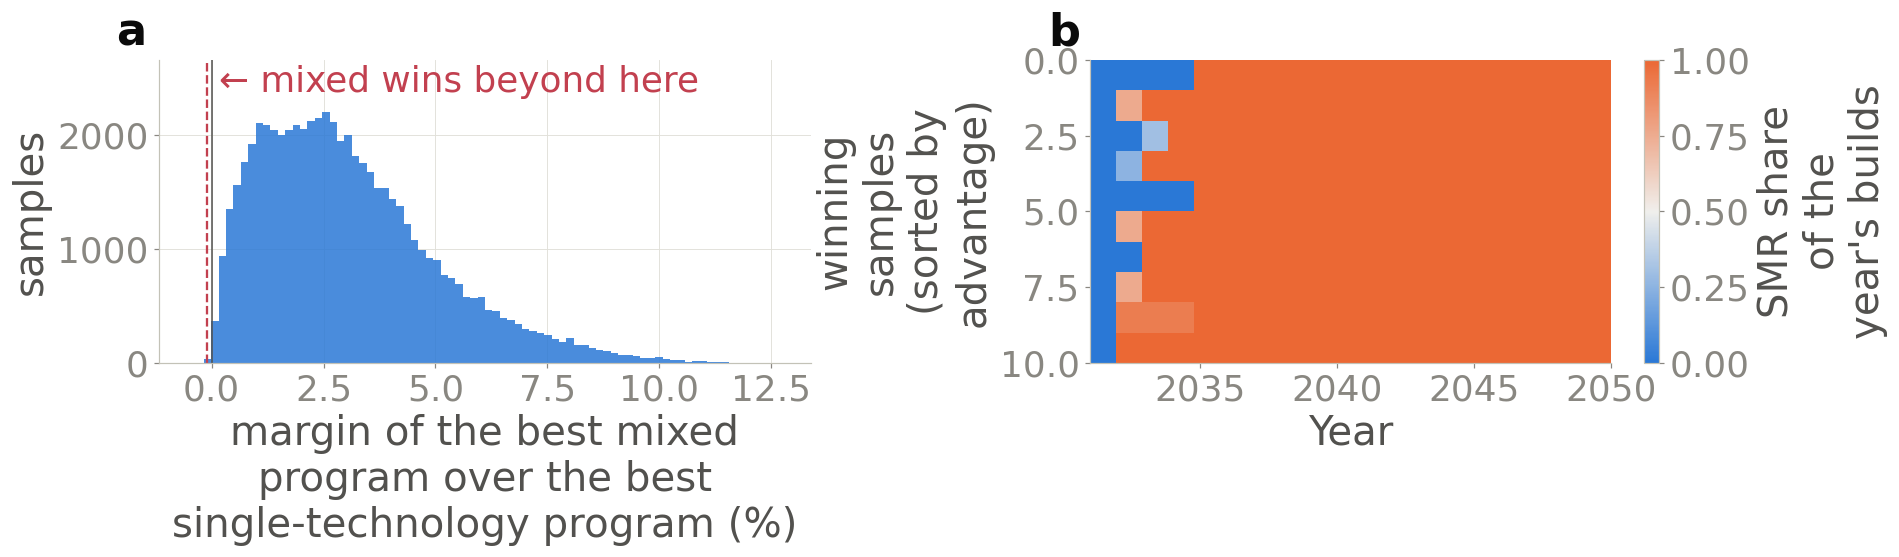

In [28]:
import matplotlib.ticker as mticker
# --- SI conventions ---------------------------------------------------------------------
# One name per thing, from nlpaper.plotstyle: the paper's target names (so no panel
# prints "Abou-Jaoude"), "sample" for a Monte Carlo draw, and the 2025 dollar multiplier
# applied where a cost axis is drawn (the exports stay in 2022 dollars).
SLAB = {s: ps.SCHED_LABEL[t] for s, t in zip(SCHED_ORDER, ps.SCHED_ORDER)}
SCHED_KEY_MB = dict(zip(SCHED_ORDER, ps.SCHED_ORDER))   # for the map titles
TO2025_MB = ps.to2025(2022)
PROG_LABEL_MB = {"large": ps.PROGRAM_LABEL["large100"], "smr": ps.PROGRAM_LABEL["smr100"],
                 "mixed": "mixed program"}
# SF5 is one page-width image made of four full-width figures, so its type is set for a
# 19.07 in canvas (the solved composite width) rather than the 6.5 in PAPER_FONT page.
SF5_W = 19.07

# Figures: the margin distribution (the whole verdict in one panel), and — if any exist —
# the winning share profiles.
_PF = ps.fonts(SF5_W)          # one type specification
plt.rcParams.update(ps.font_rc(SF5_W))
fig, axes = plt.subplots(1, 2, figsize=(17.6, 5.6))
ax = axes[0]
m_all = 100 * _all["margin"].values
ax.hist(m_all, bins=80, color=ps.ACCENT["blue"], alpha=0.85)
ax.axvline(0.0, color=ps.MUTED, lw=1)
ax.axvline(-100 * TOL_WIN, color=ps.ACCENT["red"], ls="--", lw=1.5)
# Headroom above the tallest bars, then the label just right of the threshold line,
# fully inside the axes (it used to straddle the y-spine at the figure's left edge).
_ymax = ax.get_ylim()[1]
ax.set_ylim(top=_ymax * 1.15)
ax.text(-100 * TOL_WIN + 0.02 * (m_all.max() - m_all.min()), _ymax * 1.13,
        "\u2190 mixed wins beyond here",
        color=ps.ACCENT["red"], fontsize=_PF["annotation"], va="top", ha="left")
ax.set_xlabel("margin of the best mixed\nprogram over the best\nsingle-technology program (%)")
ax.set_ylabel("samples")

ax = axes[1]
if len(winning):
    order = winning["advantage"].values.argsort()[::-1]
    heat = winning[[f"p_{y}" for y in BUILD_YEARS]].values[order]
    im = ax.imshow(heat, aspect="auto", cmap=ps.cmap_div(), vmin=0, vmax=1,
                   extent=[BUILD_YEARS[0], BUILD_YEARS[-1], len(winning), 0])
    plt.colorbar(im, ax=ax, label="SMR share\nof the\nyear's builds")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(5))   # every fifth year
    ax.set_xlabel("Year")
    ax.set_ylabel("winning\nsamples\n(sorted by\nadvantage)")
    ax.grid(False)
else:
    ax.text(0.5, 0.5, "No mixed program wins\nat the run settings",
            ha="center", va="center", fontsize=_PF["panel_title"], color=ps.MUTED,
            transform=ax.transAxes)
    ax.set_axis_off()
ps.letter_panels(axes, size=_PF["panel_letter"])
plt.tight_layout()
ps.savefig(fig, FIGURES / "mixed_build_advantage.png")
ps.apply()
plt.show()

### B9 — The parameter space: where each strategy wins

The two orderings make the contest two-dimensional. Every sample has a **starting-cost gap** (how much more the
SMR costs at the 2030 anchor) and a **learning-rate gap** (how much faster it learns). The maps chart the outcome
over that plane.

**Supplementary Figure 5, panel e: winner maps, one per target.** Each cell shows the share of samples whose
cheaper *pure* strategy is the SMR program, on the house diverging scale (blue = the large-reactor program is
cheaper, orange = the SMR program). The black contour is the 50 % boundary, and violet stars mark samples where a
mixed build wins. Larger targets spread the SMR's learning investment over more builds, so the boundary moves
with ambition; that movement is the deployment-scale effect on technology choice.

**Supplementary Figure 5, panels c and d: margin map and closest calls.** (c) The mean penalty of the best
genuinely mixed strategy over the same plane, pooled across targets. (d) The individual samples where the best
mixed strategy came within 1 % of the best pure one, coloured by the cheapest program. The near-ties hug the
decision boundary. There the two pure programs cost the same, so any blend of them also costs about the same:
mixing comes close where the choice does not matter, not where mixing creates value.

saved -> z-ethan\results\exports\03a\mixed_build_parameter_space.png


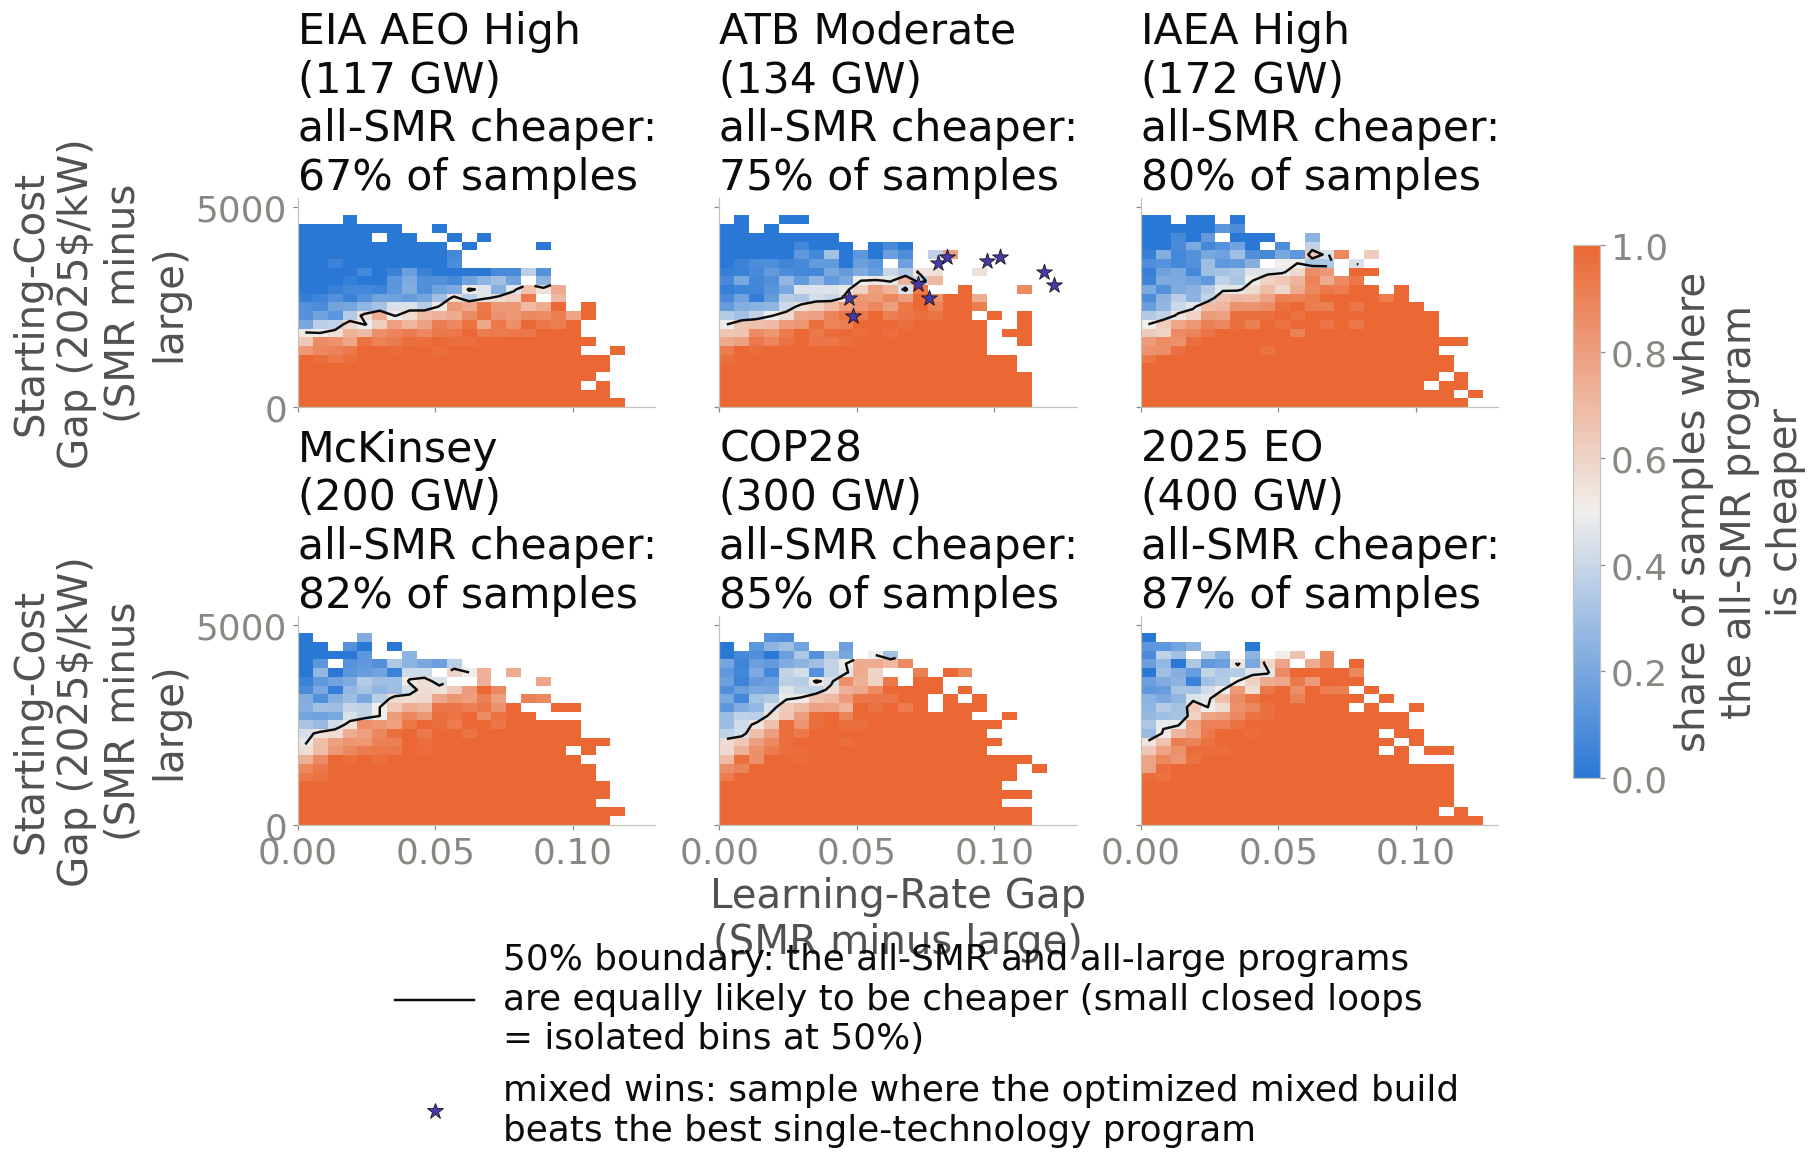

In [29]:
# Winner maps per schedule over the (lr gap, boak gap) plane.
GAP_X_EDGES = np.linspace(0.0, TECH["smr"]["lr_hi"] - TECH["large"]["lr_lo"], 25)
GAP_Y_EDGES = np.linspace(0.0, TECH["smr"]["boak_hi"] - TECH["large"]["boak_lo"], 25)
MIN_BIN = 8                                     # mask cells with fewer draws than this

def binned_rate(df, value_col=None, statistic="mean"):
    """2D binned statistic over (lr_gap, boak_gap); returns (grid, counts)."""
    cnt, _, _ = np.histogram2d(df["lr_gap"], df["boak_gap"], bins=[GAP_X_EDGES, GAP_Y_EDGES])
    if value_col is None:
        return cnt
    tot, _, _ = np.histogram2d(df["lr_gap"], df["boak_gap"], bins=[GAP_X_EDGES, GAP_Y_EDGES],
                               weights=df[value_col].astype(float))
    with np.errstate(invalid="ignore"):
        grid = np.where(cnt >= MIN_BIN, tot / cnt, np.nan)
    return grid, cnt

_PF = ps.fonts(SF5_W)
plt.rcParams.update(ps.font_rc(SF5_W))
fig, axes = plt.subplots(2, 3, figsize=(17.6, 7.4), sharex=True, sharey=True,
                         gridspec_kw={"hspace": 1.0, "wspace": 0.18})
_xc = 0.5 * (GAP_X_EDGES[:-1] + GAP_X_EDGES[1:])
_yc = 0.5 * (GAP_Y_EDGES[:-1] + GAP_Y_EDGES[1:])
_GY = GAP_Y_EDGES * TO2025_MB   # the cost axis is drawn in 2025 dollars
_yc25 = _yc * TO2025_MB
for ax, sched in zip(axes.ravel(), SCHED_ORDER):
    df = _all[_all["schedule"] == sched]
    df = df.assign(smr_win=(df["corner_winner"] == "smr").astype(float))
    grid, cnt = binned_rate(df, "smr_win")
    im = ax.pcolormesh(GAP_X_EDGES, _GY, grid.T, cmap=ps.cmap_div(),
                       vmin=0, vmax=1, shading="flat")
    masked = np.ma.masked_invalid(grid.T)
    ax.contour(_xc, _yc25, masked, levels=[0.5], colors=ps.INK, linewidths=1.6)
    mw = df[df["mixed_wins"]]
    if len(mw):
        ax.scatter(mw["lr_gap"], mw["boak_gap"] * TO2025_MB, marker="*", s=120,
                   c=ps.ACCENT["violet"], edgecolors=ps.INK, lw=0.5, zorder=5)
    p_smr = (df["corner_winner"] == "smr").mean()
    ax.set_title(f"{ps.SCHED_SHORT[SCHED_KEY_MB[sched]]}\n({ps.SCHED_GW[SCHED_KEY_MB[sched]]} GW)\nall-SMR cheaper:\n{p_smr:.0%} of samples")
    ax.grid(False)
# the grid shares its x axis, so one label under the middle panel serves all six
axes[1, 1].set_xlabel("Learning-Rate Gap\n(SMR minus large)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"Starting-Cost\nGap {ps.usd('kW', 2025)}\n(SMR minus\nlarge)")
fig.colorbar(im, ax=axes, shrink=0.85,
             label="share of samples where\nthe all-SMR program\nis cheaper")
# Figure-level key (below the grid, clear of all panels) for the overlay marks:
# the black contour is the 50% line of the plotted SMR-win share; the star marks
# individual draws where the optimized mixed build beats the best pure strategy.
from matplotlib.lines import Line2D
_key = [Line2D([], [], color=ps.INK, lw=1.6,
               label="50% boundary: the all-SMR and all-large programs\nare equally likely to be cheaper (small closed loops\n= isolated bins at 50%)"),
        Line2D([], [], marker="*", ls="none", markersize=11,
               markerfacecolor=ps.ACCENT["violet"], markeredgecolor=ps.INK,
               markeredgewidth=0.5,
               label="mixed wins: sample where the optimized mixed build\nbeats the best single-technology program")]
fig.legend(handles=_key, loc="upper center", bbox_to_anchor=(0.45, 0.005),
           frameon=False, fontsize=_PF["legend"], handlelength=2.2, ncol=1)
ps.savefig(fig, FIGURES / "mixed_build_parameter_space.png")
ps.apply()
plt.show()

saved -> z-ethan\results\exports\03a\mixed_build_margin_map.png


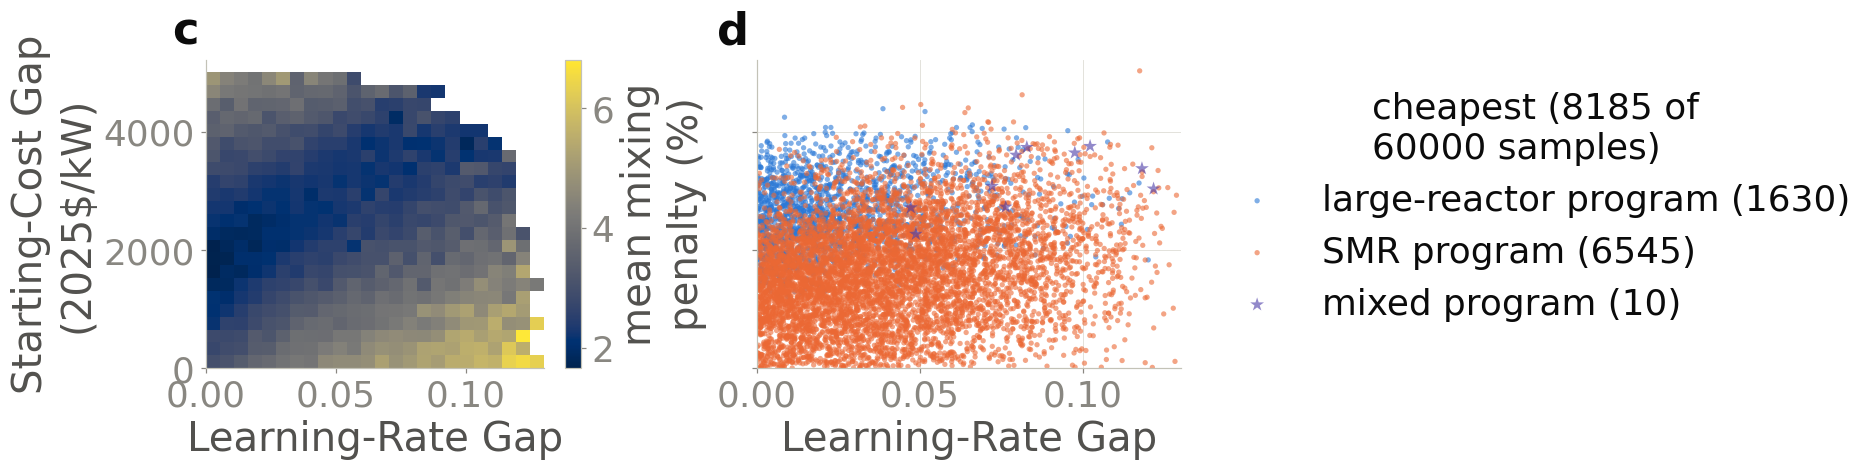

Reading the maps: the near-ties trace the decision boundary — the region where the two pure
programs cost the same, so any blend of them also costs about the same. Mixing gets close
exactly where choosing does not matter, not where mixing creates value.


In [30]:
# The margin map: how expensive is the best possible mix, across the same plane — and the
# individual draws where it came within 1% of the best pure strategy.
_PF = ps.fonts(SF5_W)
plt.rcParams.update(ps.font_rc(SF5_W))
fig, axes = plt.subplots(1, 2, figsize=(17.6, 4.8), sharex=True, sharey=True)
ax = axes[0]
grid, cnt = binned_rate(_all, "margin")
im = ax.pcolormesh(GAP_X_EDGES, _GY, 100 * grid.T, cmap=ps.CMAP_SEQ, shading="flat")
plt.colorbar(im, ax=ax, label="mean mixing\npenalty (%)")
ax.set_xlabel("Learning-Rate Gap")
ax.set_ylabel(f"Starting-Cost Gap\n{ps.usd('kW', 2025)}")
ax.grid(False)

ax = axes[1]
close = _all[_all["margin"] < 0.01]
for cat, col, ms in (("large", ps.COL["large"], 12), ("smr", ps.COL["smr"], 12),
                     ("mixed", ps.ACCENT["violet"], 90)):
    sub = close[close["winner"] == cat]
    if len(sub):
        ax.scatter(sub["lr_gap"], sub["boak_gap"] * TO2025_MB, s=ms, c=col, alpha=0.6,
                   marker="*" if cat == "mixed" else "o", edgecolors="none",
                   label=f"{PROG_LABEL_MB[cat]} ({len(sub)})")
ax.set_xlabel("Learning-Rate Gap")
# The scatter fills the axes, so park the key outside the right spine, off the data.
ax.legend(fontsize=_PF["legend"],
          title=f"cheapest ({len(close)} of\n{len(_all)} samples)",
          title_fontsize=_PF["legend"], loc="upper left",
          bbox_to_anchor=(1.02, 1.0))
# Letters continue from mixed_build_advantage (a/b): this figure is the second source
# of composed paper figure SF5, so its panels carry c and d.
ps.panel_letter(axes[0], "c", size=_PF["panel_letter"])
ps.panel_letter(axes[1], "d", size=_PF["panel_letter"])
plt.tight_layout()
ps.savefig(fig, FIGURES / "mixed_build_margin_map.png")
ps.apply()
plt.show()
print("Reading the maps: the near-ties trace the decision boundary — the region where the "
      "two pure\nprograms cost the same, so any blend of them also costs about the same. "
      "Mixing gets close\nexactly where choosing does not matter, not where mixing creates value.")

### B10 — Sensitivity: shut the spillover off

This cell re-runs the funnel on the same samples with both spillover fractions forced to zero. Comparing its
closest margins with the main run isolates how much the drawn spillover moves mixing toward viability. This is also
the limit in which notebook 01's fragmentation figure lives (QA-G checks it).

In [31]:
print("cross-tech spillover forced to zero (main draws, all schedules):")
XZERO_FUNNEL = {}
for sched in SCHED_ORDER:
    XZERO_FUNNEL[sched] = run_funnel(WORLDS[sched], sched, S_KV=SKV[sched], x_zero=True,
                                     label=f"xzero/{SCEN_TOKEN[sched]}")
xzero_tab = pd.DataFrame({s: {"P(mixed wins > 0.1%)": float(XZERO_FUNNEL[s]["mixed_wins"].mean()),
                              "closest margin": float(XZERO_FUNNEL[s]["margin"].min())}
                          for s in SCHED_ORDER}).T
xzero_tab.to_csv(EXPORTS / "xzero_verdict.csv")
print()
print(xzero_tab.round(4).to_string())
print("\nComparing 'closest margin' here vs the main run isolates how much the drawn "
      "cross-tech\nspillover moves mixing toward viability.")

cross-tech spillover forced to zero (main draws, all schedules):


  xzero/eia_aeo_high           flagged  307/10000 (near-corner 21, audit-only 286), mixed wins    0 (0.0%), closest margin +0.28%, 25s


  xzero/abou_jaoude            flagged 2945/10000 (near-corner 2736, audit-only 209), mixed wins    6 (0.1%), closest margin -0.37%, 193s


  xzero/iaea_high              flagged  320/10000 (near-corner 0, audit-only 320), mixed wins    0 (0.0%), closest margin +0.54%, 18s


  xzero/mckinsey               flagged  328/10000 (near-corner 0, audit-only 328), mixed wins    0 (0.0%), closest margin +0.53%, 27s


  xzero/cop28                  flagged  291/10000 (near-corner 0, audit-only 291), mixed wins    0 (0.0%), closest margin +0.68%, 24s


  xzero/eo2025                 flagged  301/10000 (near-corner 0, audit-only 301), mixed wins    0 (0.0%), closest margin +0.44%, 26s

                       P(mixed wins > 0.1%)  closest margin
EIA 2026 AEO high                    0.0000          0.0028
Abou-Jaoude mod                      0.0006         -0.0037
IAEA high                            0.0000          0.0054
McKinsey GEP 2025                    0.0000          0.0053
COP28 tripling pledge                0.0000          0.0068
2025 EO                              0.0000          0.0044

Comparing 'closest margin' here vs the main run isolates how much the drawn cross-tech
spillover moves mixing toward viability.


### B11 — QA suite

One check per cell; each prints PASS or FAIL. QA-A, QA-B and QA-D pin this section to notebook 01's engine at the
"off" settings. QA-C validates the ordered draw. QA-E re-pins the financing port to the ReEDS learning engine's
regression value. QA-F checks the optimizer's internal consistency. QA-G reports the shared limit (comonotone draw,
zero spillover) against the frozen 2026-08-05 fragmentation result of the Monte Carlo notebook.

In [32]:
# QA-A — engine parity: the production experience_channels (with its x_in/S_KV hot-loop
# conveniences at their neutral settings) must reproduce the companion notebook's engine
# BIT-FOR-BIT. The companion's exact function body is pasted here as the reference
# implementation (notebook 01's engine).
def _experience_channels_companion(world, tech, n_us, n_oth=None):
    n = len(world)
    u_r = np.repeat(world["u"].values[:, None], len(REGIONS), axis=1)
    if ONE_FACTOR_DELTA > 0:
        u_r = np.clip(u_r + rng_stream("one_factor_noise").uniform(
            -ONE_FACTOR_DELTA, ONE_FACTOR_DELTA, (n, len(REGIONS))), 0, 1)
    gi = np.clip(np.rint(u_r * (len(U_GRID)-1)).astype(int), 0, len(U_GRID)-1)
    S_kv = np.zeros((n, T))
    for j, r in enumerate(REGIONS):
        S_kv += THETA_KV[r] * REGION_STOCK[r][gi[:, j], :]
    S_kv = lag1(S_kv)
    N_us = lag1(np.broadcast_to(np.asarray(n_us, float), (n, T)))
    conv = world["conv_full"].values[:, None].astype(float)
    m = world["n_vendors"].values[:, None].astype(float)
    s = world["s"].values[:, None]
    hist_us = HIST_UNITS["US"] if tech == "large" else 0.0
    own0 = N_BOAK_UNITS + conv*hist_us/m
    own = own0 + N_us/m
    oth = (m-1.0)*own0 + N_us*(m-1.0)/m \
          + s*(conv*H_ALL_W + S_kv)
    if n_oth is not None:
        x = world[X_IN_COL[tech]].values[:, None]
        oth = oth + x*lag1(np.broadcast_to(np.asarray(n_oth, float), (n, T)))
    return own, oth

_w = WORLDS[REP_SCHED]
for tech in TECH:
    n_us = np.cumsum(GW_ADD[REP_SCHED]) / TECH[tech]["unit_gw"]   # tech takes the whole program
    n_oth = np.cumsum(GW_ADD[REP_SCHED]) / TECH[OTHER_TECH[tech]]["unit_gw"]
    for kwargs in ({}, {"n_oth": n_oth}):
        own_a, oth_a = experience_channels(_w, tech, n_us, **kwargs)      # conveniences off
        own_b, oth_b = experience_channels(_w, tech, n_us, S_KV=SKV[REP_SCHED],
                                           x_in=_w[X_IN_COL[tech]].values, **kwargs)
        own_c, oth_c = _experience_channels_companion(_w, tech, n_us, **kwargs)
        assert np.array_equal(own_a, own_c) and np.array_equal(oth_a, oth_c), \
            (tech, sorted(kwargs))
        assert np.array_equal(own_b, own_c) and np.array_equal(oth_b, oth_c), \
            (tech, sorted(kwargs))
print("QA-A PASSED: production experience_channels reproduces the companion engine bit-for-bit "
      "(with and without a cross-tech program; conveniences off, and explicit-x + cached stock)")

QA-A PASSED: production experience_channels reproduces the companion engine bit-for-bit (with and without a cross-tech program; conveniences off, and explicit-x + cached stock)


In [33]:
# QA-B — anchor identity: OCC(2030) equals the drawn anchor cost for EVERY draw, technology,
# and share profile, even with drawn cross-tech spillover active (the cross-tech stock is
# zero at the anchor by construction, so the anchor can never move).
_rng = rng_stream("mixopt/qa_b")
for sched in SCHED_ORDER:
    w = WORLDS[sched]
    p_full = embed_shares(_rng.random(N_P))
    n_large, n_smr = split_units(sched, p_full)
    for tech, n_own, n_oth, xcol in (("smr", n_smr, n_large, "x_ls"),
                                     ("large", n_large, n_smr, "x_sl")):
        occ = occ_paths_ces(w, tech, n_own, n_oth=n_oth, x_in=w[xcol].values, S_KV=SKV[sched])
        assert np.allclose(occ[:, yi(ANCHOR)], w[f"boak_{tech}"].values), (sched, tech)
print("QA-B PASSED: every draw hits its anchor cost exactly at 2030, "
      "all schedules, both technologies, random share profile, drawn spillover")

QA-B PASSED: every draw hits its anchor cost exactly at 2030, all schedules, both technologies, random share profile, drawn spillover


In [34]:
# QA-C — the ordered draw: both orderings hold on EVERY production draw; the conditioned
# marginals stay inside the published ranges; and the conditioning behaves as expected
# (acceptance ~50%; the SMR marginals tilt up, the large marginals tilt down — reported).
for sched in SCHED_ORDER:
    w = WORLDS[sched]
    assert (w["boak_smr"] > w["boak_large"]).all(), sched
    assert (w["lr_smr"] > w["lr_large"]).all(), sched
    for tech in TECH:
        t = TECH[tech]
        assert w[f"boak_{tech}"].between(t["boak_lo"], t["boak_hi"]).all(), (sched, tech)
        assert w[f"lr_{tech}"].between(t["lr_lo"], t["lr_hi"]).all(), (sched, tech)
_wq = pd.concat([WORLDS[s] for s in SCHED_ORDER], ignore_index=True)
print("QA-C PASSED: boak_smr > boak_large and lr_smr > lr_large on every draw; "
      "all marginals inside their published ranges")
print("conditioning tilt (median of the conditioned marginal vs the unconditioned midpoint):")
for col, lo, hi in (("boak_large", 5250, 7750), ("boak_smr", 5500, 10000),
                    ("lr_large", 0.03, 0.12), ("lr_smr", 0.03, 0.16)):
    mid = 0.5 * (lo + hi)
    print(f"  {col:11s} median {_wq[col].median():8.3f} vs midpoint {mid:8.3f}")

QA-C PASSED: boak_smr > boak_large and lr_smr > lr_large on every draw; all marginals inside their published ranges
conditioning tilt (median of the conditioned marginal vs the unconditioned midpoint):
  boak_large  median 6343.102 vs midpoint 6500.000
  boak_smr    median 8099.589 vs midpoint 7750.000
  lr_large    median    0.065 vs midpoint    0.075
  lr_smr      median    0.115 vs midpoint    0.095


In [35]:
# QA-D — objective consistency: (i) at the corners, the blended program cost equals the
# independently computed pure-technology program score; (ii) the fast single-draw path
# (WorldRow) reproduces the vectorized batch exactly.
for sched in SCHED_ORDER:
    w, skv = WORLDS[sched], SKV[sched]
    w_t = GW_ADD[sched] / DISC
    for tech, p_corner in (("large", np.zeros(N_P)), ("smr", np.ones(N_P))):
        n_us = np.cumsum(GW_ADD[sched]) / TECH[tech]["unit_gw"]
        fc = (occ_paths_ces(w, tech, n_us, S_KV=skv)
              * ccmult_grid(duration_paths(w, tech, n_us), tech) * FIN_REST[tech][None, :])
        direct = fc @ w_t
        blended = program_cost_batch(w, sched, p_corner, S_KV=skv)
        assert np.allclose(direct, blended, rtol=1e-12), (sched, tech)
_rng = rng_stream("mixopt/qa_d")
_w, _skv = WORLDS[REP_SCHED], SKV[REP_SCHED]
for _ in range(20):
    i = int(_rng.integers(len(_w)))
    p = _rng.random(N_P)
    fast = make_draw_objective(_w, i, REP_SCHED, _skv)(p)
    batch = program_cost_batch(_w, REP_SCHED, p, S_KV=_skv)[i]
    assert np.isclose(fast, batch, rtol=1e-12), i
print("QA-D PASSED: corner costs equal the independent pure-technology scores (all schedules), "
      "and the optimizer's fast single-draw path matches the vectorized batch exactly")

QA-D PASSED: corner costs equal the independent pure-technology scores (all schedules), and the optimizer's fast single-draw path matches the vectorized batch exactly


In [36]:
# QA-E — financing regression: the ported IDC multiplier still reproduces the ReEDS learning
# engine's pinned value (nuclear_learning.py self-test: 72 months, 8% nominal, schedule '6').
_ccm = ccmult_from_duration(72.0, 1.08, FIN["sched"]["large"])
assert abs(_ccm - 1.268124) < 1e-5, _ccm
print(f"QA-E PASSED: ccmult(72 mo, 8%, sched '6') = {_ccm:.6f} (ReEDS engine pin: 1.268124)")

QA-E PASSED: ccmult(72 mo, 8%, sched '6') = 1.268124 (ReEDS engine pin: 1.268124)


In [37]:
# QA-F — optimizer internal consistency: polishing can only improve on the screen; every
# winning profile is genuinely mixed; and the random audit sample checks that the free
# optimizer is not finding wins in regions the screen failed to flag.
_missed = 0
for name, fr in list(FUNNEL.items()) + [(f"xzero {s}", XZERO_FUNNEL[s]) for s in SCHED_ORDER]:
    assert (fr["best_mixed"] <= fr["screen"]["best_mixed"] * (1 + 1e-12)).all(), name
    assert np.isfinite(fr["margin"]).all(), name
    if fr["mixed_wins"].any():
        min_share = np.minimum(fr["smr_gw_share"], 1.0 - fr["smr_gw_share"])
        assert (min_share[fr["mixed_wins"]] > 0.01).all(), name
    audit_only = fr["audit"] & ~fr["near"]
    _missed += int((fr["mixed_wins"] & audit_only).sum())
if _missed:
    print(f"QA-F WARNING: {_missed} mixed wins came from audit-only draws the screen did not "
          f"flag — the screening library is too coarse; raise EPS_FLAG or AUDIT_FRAC and rerun.")
else:
    print("QA-F PASSED: polish never worsens the screen, every recorded win is genuinely "
          "mixed, and no mixed win was found on an audit-only draw (the screen flags every "
          "region the optimizer exploits)")

QA-F PASSED: polish never worsens the screen, every recorded win is genuinely mixed, and no mixed win was found on an audit-only draw (the screen flags every region the optimizer exploits)


In [38]:
# QA-G — continuity with the frozen pre-redesign limit this notebook once shared with the
# companion: legacy comonotone draw + zero cross-tech spillover (with x = 0 the engine is
# exactly the pre-redesign cross-firm form - international experience in the cross-firm
# channel, no cross-tech term). The companion's S13 has since moved to the drawn-x engine
# (its printed numbers now include cross-teaching split arms), so the reference here is the
# FROZEN 2026-08-05 figure. Reported, not asserted: different draws and draw counts.
_wg = draw_world_4(min(2000, N_DRAWS_OPT), COPULA_SET, 1.0, rng_stream("mixopt/qa_g"))
_skvg = intl_stock(_wg)
_c_half = program_cost_batch(_wg, REP_SCHED, np.full(N_P, 0.5), S_KV=_skvg, x_zero=True)
_c_corners = np.stack([program_cost_batch(_wg, REP_SCHED, CANDS[nm], S_KV=_skvg, x_zero=True)
                       for nm in ("pure_large", "pure_smr")])
_pen = 100 * (_c_half / _c_corners.min(axis=0) - 1.0)
print("QA-G (report): 50/50-mix penalty at comonotone anchors + zero cross-tech spillover "
      f"(the exact pre-redesign engine), {REP_SCHED}:")
print(f"  this notebook : median {np.percentile(_pen, 50):.1f}%, P90 {np.percentile(_pen, 90):.1f}%, "
      f"negative in {(_pen < 0).mean():.1%} of draws")
print("  frozen 2026-08-05 companion S13: median ~20.2%, P90 ~42% (its own draws and stream) — "
      "same ballpark expected, not asserted")

QA-G (report): 50/50-mix penalty at comonotone anchors + zero cross-tech spillover (the exact pre-redesign engine), McKinsey GEP 2025:
  this notebook : median 17.3%, P90 36.0%, negative in 0.0% of draws
  frozen 2026-08-05 companion S13: median ~20.2%, P90 ~42% (its own draws and stream) — same ballpark expected, not asserted


### B12 — Run metadata

This cell writes `mixed_build/mixed_build_metadata.json`: the seed, the switches, the headline counts, the git
commit of the repository and a short SHA-256 of each export.

In [39]:
import hashlib
import subprocess
from datetime import datetime, timezone

def _sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]

try:
    _git = subprocess.run(["git", "rev-parse", "HEAD"], cwd=paths.REPO,
                          capture_output=True, text=True).stdout.strip()
except Exception:
    _git = "unavailable"

meta = {
    "notebook": "03a_npv_and_mixed_build.ipynb (Section B; port of mixed_build_optimizer.ipynb)",
    "generated_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "fork_git_head": _git,
    "master_seed": MASTER_SEED,
    "stream_prefix": "mixopt/",
    "draw_design": "independent per-tech (lr, boak) pairs, rejection-conditioned on "
                   "boak_smr > boak_large and lr_smr > lr_large",
    "switches": {"X_SPILL_MAX": X_SPILL_MAX, "HIST_CROSS_TECH": HIST_CROSS_TECH,
                 "COPULA_SET": COPULA_SET, "N_DRAWS_OPT": N_DRAWS_OPT,
                 "EPS_FLAG": EPS_FLAG, "AUDIT_FRAC": AUDIT_FRAC, "TOL_WIN": TOL_WIN,
                 "REP_SCHED": REP_SCHED},
    "headline": {"total_draws": int(total_draws), "total_mixed_wins": int(total_wins),
                 "win_fraction": float(total_wins / total_draws),
                 "closest_margin": float(min(FUNNEL[s]["margin"].min() for s in SCHED_ORDER))},
    "exports": {p.name: _sha256(p) for p in sorted(EXPORTS.glob("*.csv"))},
}
with open(EXPORTS / "mixed_build_metadata.json", "w") as f:
    json.dump(meta, f, indent=2)
print(json.dumps(meta, indent=2))

{
  "notebook": "03a_npv_and_mixed_build.ipynb (Section B; port of mixed_build_optimizer.ipynb)",
  "generated_utc": "2026-10-22T19:23:49+00:00",
  "fork_git_head": "94a514dc471d93ad5ba6786ee620102397ca7b52",
  "master_seed": 20260715,
  "stream_prefix": "mixopt/",
  "draw_design": "independent per-tech (lr, boak) pairs, rejection-conditioned on boak_smr > boak_large and lr_smr > lr_large",
  "switches": {
    "X_SPILL_MAX": 0.3,
    "HIST_CROSS_TECH": false,
    "COPULA_SET": "moderate",
    "N_DRAWS_OPT": 10000,
    "EPS_FLAG": 0.005,
    "AUDIT_FRAC": 0.03,
    "TOL_WIN": 0.001,
    "REP_SCHED": "McKinsey GEP 2025"
  },
  "headline": {
    "total_draws": 60000,
    "total_mixed_wins": 10,
    "win_fraction": 0.00016666666666666666,
    "closest_margin": -0.005085963315268005
  },
  "exports": {
    "verdict_by_schedule.csv": "40f82d033263da26",
    "winning_draws.csv": "8b92eaa1584cdc55",
    "xzero_verdict.csv": "b8626ccb8b021edd"
  }
}


### What Section B shows

Read the verdict table as the answer to one question. Grant mixing every advantage that can be defended: up to
30 % cross-technology spillover in each direction, freely varying starting-cost and learning-rate gaps (with the SMR
always dearer at the start and always faster-learning), and a per-sample optimizer free to choose any year-by-year
split. How often, and by how much, does any mixed program beat committing to the better technology? The maps place
the answer in the parameter space. Together with the fragmentation penalty of notebook 01, this is the evidence for
the paper's winner-take-all treatment of the deployment mandate.

## Section C — Supplementary Figure 5

This cell composes Supplementary Figure 5 from four source images, one per row, at their native pixel size (the
house rule: never re-plot an existing figure). Rows 1–3 are Section B's panels, which carry their own letters a–d;
the composer stamps **e** on the winner maps. Row 4 is notebook 01's fragmentation histogram, which carries its own
letter f. The letter size is the one the paper's composite used (`ps.fonts(16.57)`).

**Panel f** is the fragmentation penalty: the extra program cost of a 50/50 split under the McKinsey target
(median about 17 %). The published panel f still carries the labels of before 2026-09-18; notebook 01 emits it.

**How to read it.** Mixes win in 10 of 60,000 samples, by at most about 0.5 %. The near-ties sit on the boundary
between the two pure programs, where the choice does not matter.

composed -> z-ethan\results\figures\si\SF05_mixed_build.png  (5266x7597 px)
wrote z-ethan\results\figures\si\SF05_mixed_build.png  (5266 x 7597 px)


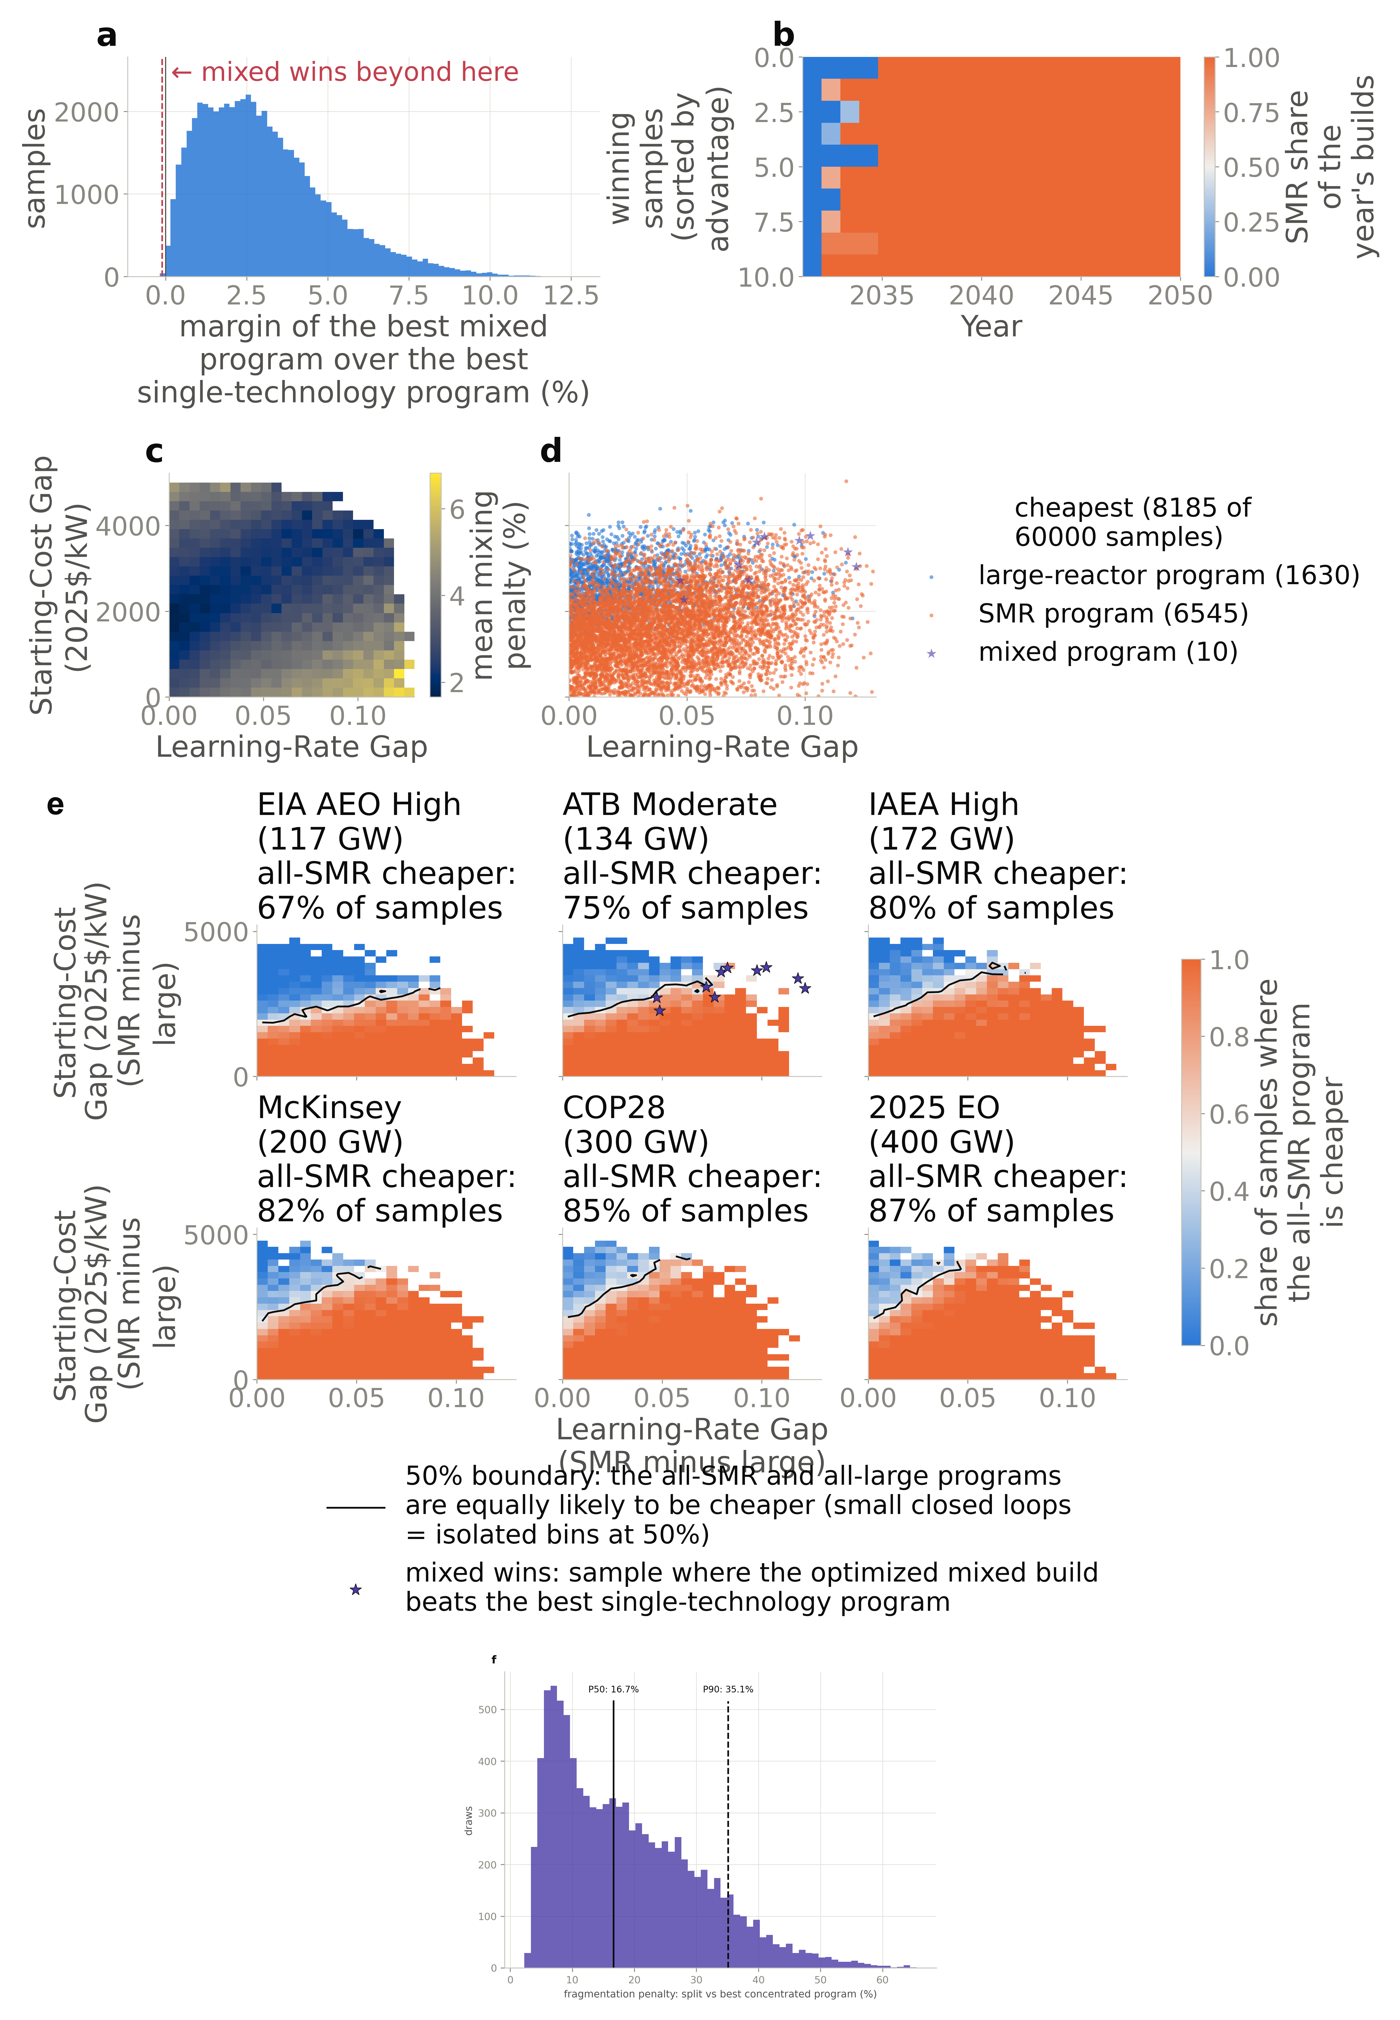

In [40]:
from nlpaper import compose as C

frag = paths.require(paths.exports("01") / "fragmentation_hist.png", "notebook 01_monte_carlo_cost_engine")
C.compose(
    [[FIGURES / "mixed_build_advantage.png"],
     [FIGURES / "mixed_build_margin_map.png"],
     [FIGURES / "mixed_build_parameter_space.png"],
     [frag]],
    paths.FIGS_SI / "SF05_mixed_build.png",
    letters=["", "", "e", ""],   # sources 1/2 carry a,b / c,d; the histogram carries f
    letter_pt=ps.fonts(19.19)["panel_letter"],   # 19.19 in reproduces the panel-letter size of the submitted SF5 composite pixel for pixel
                                              # (the internal builder constant 16.57 and the later solved 18.07 both print it smaller)
    center=True,                 # the single-panel histogram row is narrower than the map row
    show=False,
)
from PIL import Image
_im = Image.open(paths.FIGS_SI / "SF05_mixed_build.png")
print(f"wrote {paths.rel(paths.FIGS_SI / 'SF05_mixed_build.png')}  ({_im.width} x {_im.height} px)")
_im.thumbnail((1400, 2100))
display(_im.convert("RGB"))